# Amortized methods in geostatistics

In [1]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

import numpy as np

import random
from tqdm import tqdm
import time
import os
import torchmin
import joblib

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

In [3]:
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
from scipy.optimize import minimize
import scipy.linalg as linalg
from scipy.special import gamma, kv

In [4]:
import gstlearn as gl
import gstlearn.plot as gp
import gstlearn.document as gdoc
gdoc.setNoScroll()

<IPython.core.display.Javascript object>

In [5]:
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")

## Variables

In [6]:
data_path = "data/super_adv-sep_spatiotemporal_2D_bis" # "data/adv-sep_spatiotemporal_2D"

os.makedirs(data_path, exist_ok=True)
os.makedirs(data_path+"/adv/train/samples", exist_ok=True)
os.makedirs(data_path+"/adv/test/samples", exist_ok=True)
os.makedirs(data_path+"/sep/train/samples", exist_ok=True)
os.makedirs(data_path+"/sep/test/samples", exist_ok=True)

In [7]:
res_path = "results/super_spationtemporal_2D_bis"

os.makedirs(res_path, exist_ok=True)
os.makedirs(res_path+"/adv/loss_evolution", exist_ok=True)
os.makedirs(res_path+"/adv/conclusion_graphs", exist_ok=True)
os.makedirs(res_path+"/adv/models", exist_ok=True)
os.makedirs(res_path+"/sep/loss_evolution", exist_ok=True)
os.makedirs(res_path+"/sep/conclusion_graphs", exist_ok=True)
os.makedirs(res_path+"/sep/models", exist_ok=True)

In [102]:
batch_size = 50
n_epochs = 250
n_epochs_test = 10

In [206]:
space_size = 30
time_size = 30
deepset_size = 2 # 2
missing_ratio = 3/4 # 1/2

train_size = 16 # 10000
test_size = 5

## Utils

In [9]:
theta_names_adv = ["advection", "range time", "range space", "std"]
theta_names_sep = ["separability", "scale time", "scale space", "sill"]

theta_colors = [
    {
        "train":"orangered",
        "test":"lightsalmon",
        "baseline":"dimgrey"
    },
    {
        "train":"deepskyblue",
        "test":"lightskyblue",
        "baseline":"dimgrey"
    },
    {
        "train":"forestgreen",
        "test":"limegreen",
        "baseline":"dimgrey"
    },
    {
        "train":"darkorchid",
        "test":"orchid",
        "baseline":"dimgrey"
    },
]

In [10]:
def add_missing_mask(batch, missing_ratio):
    space_size = batch.shape[-1]
    nb_missing = int(space_size * missing_ratio)
    nb_visible = space_size - nb_missing

    batch = batch.copy()

    if nb_visible <= (space_size + 1) // 2:
        max_index = space_size - (nb_visible - 1)
        base = np.random.choice(max_index, size=nb_visible, replace=False)
        base = np.sort(base)
        visibles = base + np.arange(nb_visible)
    else:
        visibles = np.random.choice(space_size, size=nb_visible, replace=False)

    mask = np.ones_like(batch)
    mask[:, :, :, visibles] = 0

    batch[:, :, :, mask[0, 0, 0] == 1] = 0

    return np.concatenate([batch, mask], axis=1)

In [11]:
def deepset_collate(batch):
    data, theta, deepset = map(torch.stack, zip(*batch))

    data = data.flatten(0, 1)     
    theta = theta.flatten(0, 1)  
    deepset = deepset.flatten(0, 1)

    return data, theta, deepset

In [12]:
def unique_preserve_order(x):
    seen = []
    out = []
    for v in x.tolist():
        if v not in seen:
            seen.append(v)
            out.append(v)
    return torch.tensor(out, device=x.device)


def map_deepset(deepset, theta):
    unique_ds = unique_preserve_order(deepset)

    deepset_mapped = torch.tensor(
        [unique_ds.tolist().index(int(ds)) for ds in deepset],
        device=device
    )

    theta = torch.stack([theta[deepset == v][0] for v in unique_ds])

    return deepset_mapped, theta

In [13]:
def baseline_mae(dataset):
    all_thetas = dataset.get_theta()
    
    theta_mean = all_thetas.mean(dim=0) 
    
    preds = theta_mean.unsqueeze(0).repeat(len(dataset), 1)
    
    mae = torch.mean(torch.abs(preds - all_thetas),dim=0)

    return mae, theta_mean

In [14]:
def global_mean_pool(x, deepset):
    num_groups = deepset.max().item() + 1
    out = torch.zeros(num_groups, x.size(1), device=x.device)
    out.index_add_(0, deepset, x)
    return out / torch.bincount(deepset).float().unsqueeze(1)

## Simulation and Load : Advection

In [207]:
def simulate_matern_grid(time_size, space_size, adv, range_time, range_space, std, deepset_size=5):
    
    model = gl.Model.createFromParam(gl.ECov.MATERN, ranges = [range_time,range_space], param = 1, sill = std**2, flagRange=False)

    shape_adv = abs(adv)+1

    grid = gl.DbGrid.create(
        nx = [time_size,space_size  + time_size*shape_adv],    
        dx = [1./time_size,1./space_size]
    )

    mesh = gl.MeshETurbo(grid)

    pop = gl.PrecisionOpMatrix(mesh, model.getCovAniso(0))

    batch = []
        
    for i in range(deepset_size):
            
        res = pop.simulateOne()
        res = res.reshape((time_size,space_size + time_size*shape_adv), order='F')

        t, s = np.meshgrid(np.arange(time_size), np.arange(space_size), indexing='ij')
        offset = t.copy() * abs(adv)
        s = s + offset


        if adv >= 0 :
            res = res[t,s]
        else :
            res = np.fliplr(res)
            res = res[t,s]
            res = np.fliplr(res)
            
        batch.append(res)

    return np.expand_dims(np.stack(batch),1)

In [208]:
class GridDataset(Dataset):
    def __init__(self, theta_size=200, time_size=40, space_size=40, deepset_size=5, missing_ratio=0):

        self.time_size = time_size
        self.space_size = space_size
        
        self.theta_size = theta_size
        self.deepset_size = deepset_size

        self.adv = np.random.randint(-3,4,(theta_size,)) # np.ones((theta_size,), dtype=int)*-1
        self.range_time = np.random.uniform(0.05,0.25,(theta_size,)) 
        self.range_space = np.random.uniform(0.05,0.25,(theta_size,))
        self.std = np.random.uniform(0.1,1.,(theta_size,))

        self.missing_ratio = missing_ratio

        self.path = None
        self.time_generation = None

    def __len__(self):
        return self.theta_size

    def get_theta(self):
        return torch.from_numpy(np.stack([self.adv,self.range_time, self.range_space, self.std]).T)

    def save(self, path):
        param = {
            "time_size" : self.time_size,
            "space_size" : self.space_size,
            "theta_size" : self.theta_size,
            "deepset_size" : self.deepset_size,
            "missing_ratio" : self.missing_ratio,
            "adv" : self.adv,
            "range_time" : self.range_time,
            "range_space" : self.range_space,
            "std" : self.std,
            "time_generation" : self.time_generation,
        }
        np.save(f"{path}/thetas.npy", param)  
        self.path = path

    @classmethod
    def load(cls, path):

        param = np.load(f"{path}/thetas.npy", allow_pickle=True).item()

        instance = cls(
            theta_size=param["theta_size"],
            time_size=param["time_size"],
            space_size=param["space_size"],
            deepset_size=param["deepset_size"],
            missing_ratio=param["missing_ratio"]
        )

        instance.adv = param["adv"]
        instance.range_time = param["range_time"]
        instance.range_space = param["range_space"]
        instance.std = param["std"]
        instance.time_generation = param.get("time_generation", None)

        instance.path = path

        return instance

    def generate(self, path):

        t = tqdm(range(0, self.theta_size),total=self.theta_size)
        time_generation = time.time()

        for idx in t:

            batch = simulate_matern_grid(
                self.time_size, self.space_size, 
                self.adv[idx], self.range_time[idx], self.range_space[idx],
                self.std[idx],
                self.deepset_size
            )

            np.save(f"{path}/samples/sample_{idx}.npy",batch) 

        self.time_generation = time.time() - time_generation
        
        self.save(path)

    def get_fulldata_mask(self, idx):

        batch = np.load(f"{self.path}/samples/sample_{idx}.npy")

        if self.missing_ratio > 0 :
            batch_mask = add_missing_mask(batch.copy(), self.missing_ratio)[0]

        batch_mask[0] = batch[0]
        
        theta = self.get_theta()[idx]

        return (batch_mask, theta)   
    
    def __getitem__(self, idx):

        batch = np.load(f"{self.path}/samples/sample_{idx}.npy")

        if self.missing_ratio > 0 :
            batch = add_missing_mask(batch, self.missing_ratio)

        theta = self.get_theta()[idx].tile(self.deepset_size,1)

        deepset = torch.ones(self.deepset_size, dtype=int) * idx # torch.tensor([i for i in range(self.deepset_size) if not(theta[i] in theta[:i])])

        return (torch.from_numpy(batch), theta, deepset)           

In [209]:
dataset_grid = GridDataset(theta_size=train_size, time_size=time_size, space_size=space_size, deepset_size=deepset_size,missing_ratio=missing_ratio)
dataset_grid_test = GridDataset(theta_size=test_size, time_size=time_size, space_size=space_size, deepset_size=1,missing_ratio=missing_ratio)

dataset_grid.generate(data_path+"/adv/train")
dataset_grid_test.generate(data_path+"/adv/test")

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00, 62.36it/s]


In [210]:
dataset_grid = GridDataset.load(data_path+"/adv/train")
dataset_grid_test = GridDataset.load(data_path+"/adv/test")

In [211]:
loader_grid = DataLoader(dataset_grid, batch_size=batch_size, shuffle=True,collate_fn=deepset_collate)
loader_grid_test = DataLoader(dataset_grid_test, test_size, shuffle=False,collate_fn=deepset_collate)

time_simu_grid = dataset_grid.time_generation + dataset_grid_test.time_generation

Text(0.5, 1.0, 'mask')

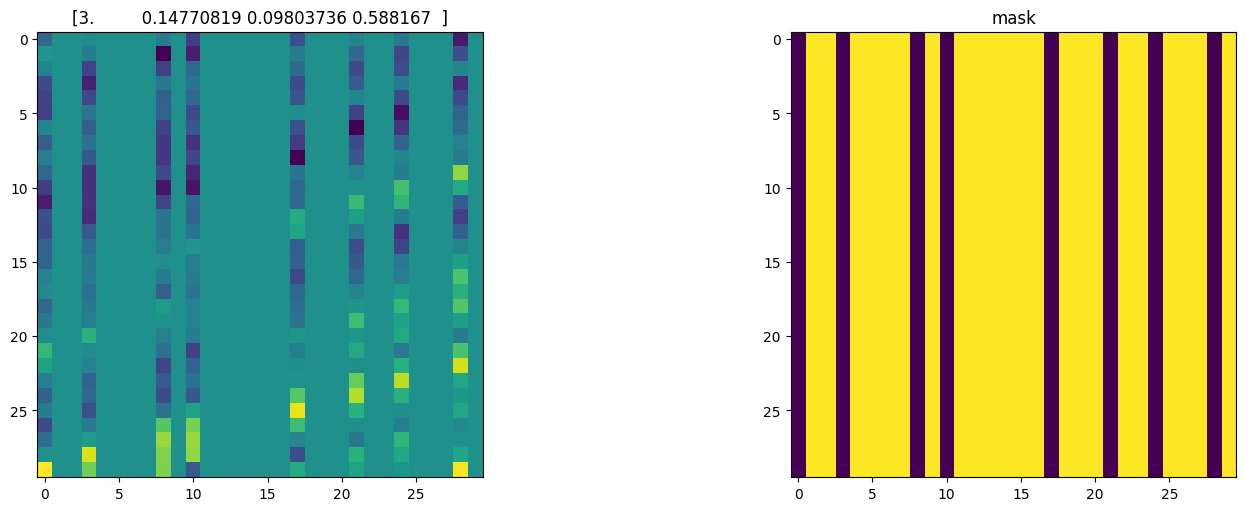

In [212]:
m=0
im = dataset_grid[0]
fig, ax = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
ax[0].imshow(im[0][m][0], aspect='equal')
ax[0].set_title(im[1][m].detach().numpy())
ax[1].imshow(im[0][m][1], aspect='equal')
ax[1].set_title("mask")

Text(0.5, 1.0, '[0.         0.06630929 0.16131594 0.9099327 ]')

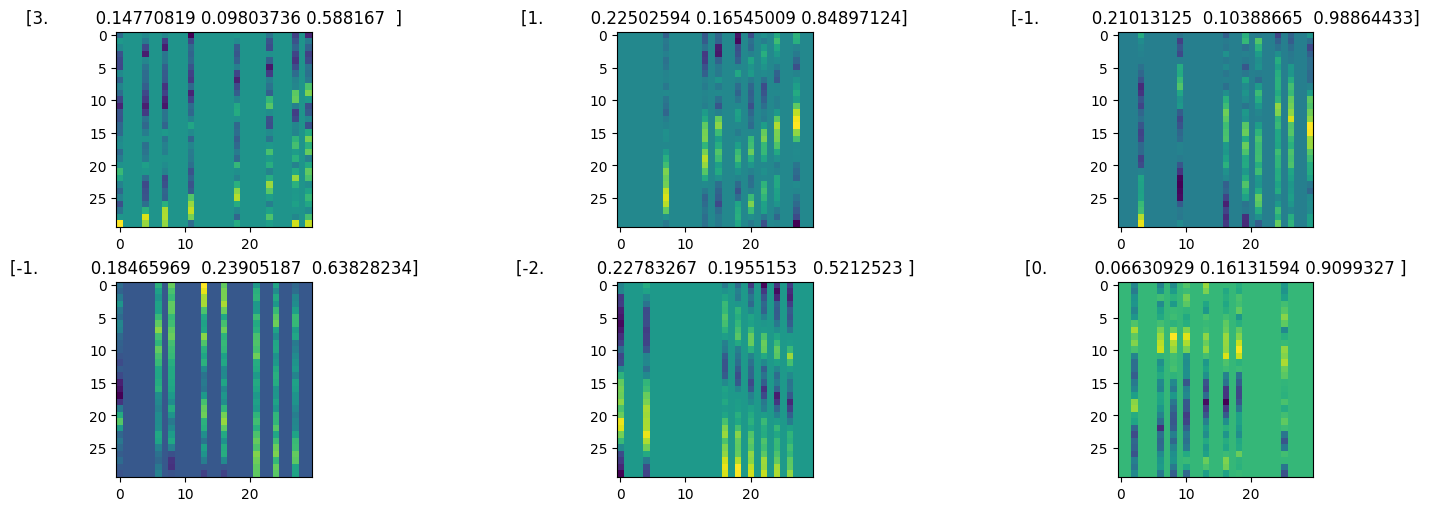

In [213]:
m=0
fig, ax = plt.subplots(2, 3, figsize=(15, 5), constrained_layout=True)
ax[0,0].imshow(dataset_grid[0][0][m][0], aspect='equal')
ax[0,0].set_title(dataset_grid[0][1][m].detach().numpy())
ax[0,1].imshow(dataset_grid[1][0][m][0], aspect='equal')
ax[0,1].set_title(dataset_grid[1][1][m].detach().numpy())
ax[0,2].imshow(dataset_grid[2][0][m][0], aspect='equal')
ax[0,2].set_title(dataset_grid[2][1][m].detach().numpy())
ax[1,0].imshow(dataset_grid[3][0][m][0], aspect='equal')
ax[1,0].set_title(dataset_grid[3][1][m].detach().numpy())
ax[1,1].imshow(dataset_grid[4][0][m][0], aspect='equal')
ax[1,1].set_title(dataset_grid[4][1][m].detach().numpy())
ax[1,2].imshow(dataset_grid[5][0][m][0], aspect='equal')
ax[1,2].set_title(dataset_grid[5][1][m].detach().numpy())

## Simulation and Load : 

⏳

## Simulation and Load : Gneiting

In [167]:
def variogram(u, alpha=1.0, b=1.0):
    """Variogram: gamma(u) = (|u|/b)^alpha"""
    return (np.abs(u) / b) ** alpha

def matern_cov(h, nu=1.5, a=1.0):
    """Matern isotropic covariance function"""
    d = np.abs(h)
    res = np.ones_like(d)
    mask = d > 0
    
    if np.any(mask):
        d_val = d[mask]
        const = 2.0 / gamma(nu)
        term = (d_val / (2.0 * a)) ** nu
        bessel = kv(nu, d_val / a)
        res[mask] = const * term * bessel
        
    return res

def sim_w(p, Nt, params):
    """
    Simulates p copies of temporal processes W with temporal variogram 
    gamma*(u) = (gamma(u)+1)^beta - 1
    """
    # Params: [nu, a, alpha, b, beta, delta, k]
    alpha, b_param, beta = params[2], params[3], params[4]

    t_indices = np.arange(1, Nt + 1)
    
    c1 = (variogram(-t_indices, alpha=alpha, b=b_param) + 1.0) ** beta - 1.0
    
    diff_matrix = t_indices[:, None] - t_indices[None, :]
    cc_term = (variogram(diff_matrix, alpha=alpha, b=b_param) + 1.0) ** beta - 1.0
    
    cc = c1[:, None] + c1[None, :] - cc_term
    
    L = np.linalg.cholesky(cc + 1e-10 * np.eye(Nt))
    
    X = np.random.normal(size=(Nt, p))
    
    W = L @ X
    return W.T 

def sim_z1(p, Nt, params):
    """
    Simulates p copies of temporal processes Z1 with temporal covariance function
    gamma*(u) = (gamma(u)+1)^(-delta)
    """
    alpha, b_param, delta = params[2], params[3], params[5]

    t_indices = np.arange(1, Nt + 1)
    diff_matrix = t_indices[:, None] - t_indices[None, :]
    cc = 1.0 / (variogram(diff_matrix, alpha=alpha, b=b_param) + 1.0) ** delta
    
    L = np.linalg.cholesky(cc + 1e-10 * np.eye(Nt))
    X = np.random.normal(size=(Nt, p))
    
    Z = L @ X
    return Z.T # (p, Nt)

def sim_rvs(p, params):
    """
    Simulates all necessary Random Variables for the 
    spectral band simulation algorithm with substitution approach
    """
    nu, a = params[0], params[1]
    k = params[6] 
    
    r_gamma = np.random.gamma(shape=nu, scale=2 * (a**2), size=p)
    
    R_val = 1.0 / (2.0 * r_gamma)
    multR = np.sqrt(2.0 * R_val)
    
    Phi = 2 * np.pi * np.random.uniform(size=p)
    
    U_rand = np.random.uniform(size=p)
    UU = np.sqrt(-2.0 * np.log(U_rand))
    
    Omega = np.random.normal(size=(k, p))
    
    return {
        "UU": UU,       # (p,)
        "multR": multR, # (p,)
        "Omega": Omega, # (k, p)
        "Phi": Phi      # (p,)
    }

def ztilde_t_vecs(s, t_idx, rvs, W, Z1, sigma):
    """
    Do the computation of the simulated RF
    s: coordinates (Ns, k)
    t_idx: time (0 to Nt-1)
    """
    UU = rvs["UU"]       
    multR = rvs["multR"] 
    Omega = rvs["Omega"] 
    Phi = rvs["Phi"]     
    
    nOmega = np.linalg.norm(Omega, axis=0) # (p,)
    
    ww_t = W[:, t_idx]   # (p,)
    zz_t = Z1[:, t_idx]  # (p,)
    
    p = len(UU)
    
    spatial_proj = s @ Omega 
    term_cos = (spatial_proj * multR) + (nOmega * ww_t / np.sqrt(2)) + Phi
    V = np.cos(term_cos)
    
    V = V * UU * zz_t
    
    field_t = np.sum(V, axis=1) / np.sqrt(p)
    
    return field_t * sigma

def simulate_spatio_temporal(params_dict, Nt, s_coords):
    """Eq (14), Allard et al. 2025"""
    k = 1
    p = 3000 

    # les noms dans geomodel
    nu = params_dict['smooth_s']
    a = params_dict['scale_s']
    alpha = params_dict['power_t'] 
    b = params_dict['scale_t']
    bet = params_dict['sep']
    
    delta = params_dict['power2_t'] - bet * k / 2   # sep = tau | Allard et al. 2025
    
    sim_params = [nu, a, alpha, b, bet, delta, k]
    
    sigma = np.sqrt(params_dict['sill'])
    
    t0 = time.time()
    W = sim_w(p, Nt, sim_params)   # (p, Nt)
    Z1 = sim_z1(p, Nt, sim_params) # (p, Nt)
    RVs = sim_rvs(p, sim_params)
    
    Ns = s_coords.shape[0]
    Z_field = np.zeros((Ns, Nt))
    
    # Loop on time (space in vectorized)
    for t in range(Nt):
        Z_field[:, t] = ztilde_t_vecs(s_coords, t, RVs, W, Z1, sigma)
            
    return Z_field

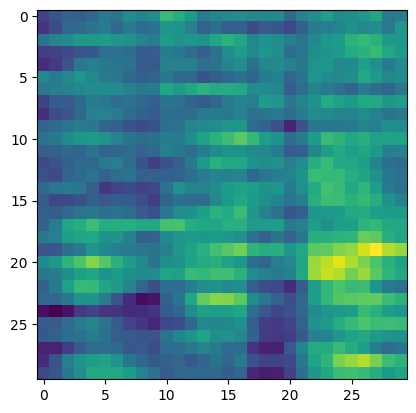

In [168]:
Ns_side = 30
Nt = 30
    
s = np.expand_dims(np.arange(1, Ns_side + 1),1)
    
params = {
    # Advection ?
    'mean': 0,
    'sill': 1.0,       #* std ?
    'smooth_s': 1.0,   #  Matérn Shape parameter 
    'scale_s': 4.0,    #* Spatial range parameter
    'power_t': 0.5,    #  Shape parameter (of the variogram \gamma(u) used in time)
    'scale_t': 1.,     #* Range parameter in time (of the variogram \gamma(u) used in time)
    'sep': 0.2,        #* Separability parameter (between 0 and 1)
    'power2_t': 0.4    #  Power in the time covariance of the time process ( > 0 )
}
    
Z_sim = simulate_spatio_temporal(params, Nt, s).T
plt.imshow(Z_sim)

In [202]:
class SepDataset(Dataset):
    def __init__(self, theta_size=200, time_size=40, space_size=40, deepset_size=5, missing_ratio=0):

        self.time_size = time_size
        self.space_size = space_size
        
        self.theta_size = theta_size
        self.deepset_size = deepset_size

        self.sep = np.random.uniform(0.01,1.,(theta_size,))
        self.power2_t = np.random.uniform(self.sep,np.ones_like(self.sep)*3,(theta_size,))
        self.scale_time = np.random.uniform(1.,5.,(theta_size,)) 
        self.scale_space = np.random.uniform(1.,5.,(theta_size,))
        self.sill = np.random.uniform(.1,1.,(theta_size,))**2 

        # self.sep = np.array([0.2,.5,1.,2., .5,.5,.5,.5,.5,.5,.5,.5,.5,.5,.5,.5])
        # self.scale_time = np.array([1.5,1.5,1.5,1.5, 1.,1.5,3.,5, 1.5,1.5,1.5,1.5,1.5,1.5,1.5,1.5])
        # self.scale_space = np.array([1.5,1.5,1.5,1.5,1.5,1.5,1.5,1.5, 1.,2.,3.,5, 1.5,1.5,1.5,1.5])
        # self.sill = np.array([.1,.1,.1,.1,.1,.1,.1,.1,.1,.1,.1,.1, .01,.1,.5,1.])

        self.missing_ratio = missing_ratio

        self.path = None
        self.time_generation = None

    def __len__(self):
        return self.theta_size

    def get_theta(self):
        return torch.from_numpy(np.stack([self.sep,self.power2_t,self.scale_time, self.scale_space, self.sill]).T)

    def save(self, path):
        param = {
            "time_size" : self.time_size,
            "space_size" : self.space_size,
            "theta_size" : self.theta_size,
            "deepset_size" : self.deepset_size,
            "missing_ratio" : self.missing_ratio,
            "sill" : self.sill,
            "scale_time" : self.scale_time,
            "scale_space" : self.scale_space,
            "sep" : self.sep,
            "power2_t" : self.power2_t,
            "time_generation" : self.time_generation,
        }
        np.save(f"{path}/thetas.npy", param)  
        self.path = path

    @classmethod
    def load(cls, path):

        param = np.load(f"{path}/thetas.npy", allow_pickle=True).item()

        instance = cls(
            theta_size=param["theta_size"],
            time_size=param["time_size"],
            space_size=param["space_size"],
            deepset_size=param["deepset_size"],
            missing_ratio=param["missing_ratio"]
        )

        instance.sep = param["sep"]
        instance.power2_t = param["power2_t"]
        instance.scale_time = param["scale_time"]
        instance.scale_space = param["scale_space"]
        instance.sill = param["sill"]
        instance.time_generation = param.get("time_generation", None)

        instance.path = path

        return instance

    def generate(self, path):

        t = tqdm(range(0, self.theta_size),total=self.theta_size)
        time_generation = time.time()

        s = np.expand_dims(np.arange(1, self.space_size + 1),1)

        for idx in t:

            batch = []
            for i in range(self.deepset_size):
    
                params = {
                    'mean': 0,
                    'sill': self.sill[idx],       
                    'smooth_s': 1.0,   
                    'scale_s': self.scale_space[idx],    
                    'power_t': 1.,    
                    'scale_t': self.scale_time[idx],     
                    'sep': self.sep[idx]   ,        
                    'power2_t': self.power2_t[idx]    
                }
                
                batch.append(simulate_spatio_temporal(params, self.time_size, s).T)
            batch = np.expand_dims(np.stack(batch), 1)

            np.save(f"{path}/samples/sample_{idx}.npy",batch) 

        self.time_generation = time.time() - time_generation
        
        self.save(path)

    def get_fulldata_mask(self, idx):

        batch = np.load(f"{self.path}/samples/sample_{idx}.npy")

        if self.missing_ratio > 0 :
            batch_mask = add_missing_mask(batch.copy(), self.missing_ratio)[0]

        batch_mask[0] = batch[0]
        
        theta = self.get_theta()[idx]

        return (batch_mask, theta)  

    
    def __getitem__(self, idx):

        batch = np.load(f"{self.path}/samples/sample_{idx}.npy")

        if self.missing_ratio > 0 :
            batch = add_missing_mask(batch, self.missing_ratio)

        theta = self.get_theta()[idx].tile(self.deepset_size,1)

        deepset = torch.ones(self.deepset_size, dtype=int) * idx # torch.tensor([i for i in range(self.deepset_size) if not(theta[i] in theta[:i])])

        return (torch.from_numpy(batch), theta, deepset)           

In [203]:
dataset_sep = SepDataset(theta_size=train_size, time_size=time_size, space_size=space_size, deepset_size=deepset_size,missing_ratio=missing_ratio)
dataset_sep_test = SepDataset(theta_size=test_size, time_size=time_size, space_size=space_size, deepset_size=1,missing_ratio=missing_ratio)

dataset_sep.generate(data_path+"/sep/train")
dataset_sep_test.generate(data_path+"/sep/test")

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00, 11.10it/s]


In [204]:
def to_title(vals):
    return f"sep : {vals[0]:.2f}\npower2_t : {vals[1]:.2f}\nscale time : {vals[2]:.1f}\nscale space : {vals[3]:.1f}\nsill : {vals[4]:.3f}"

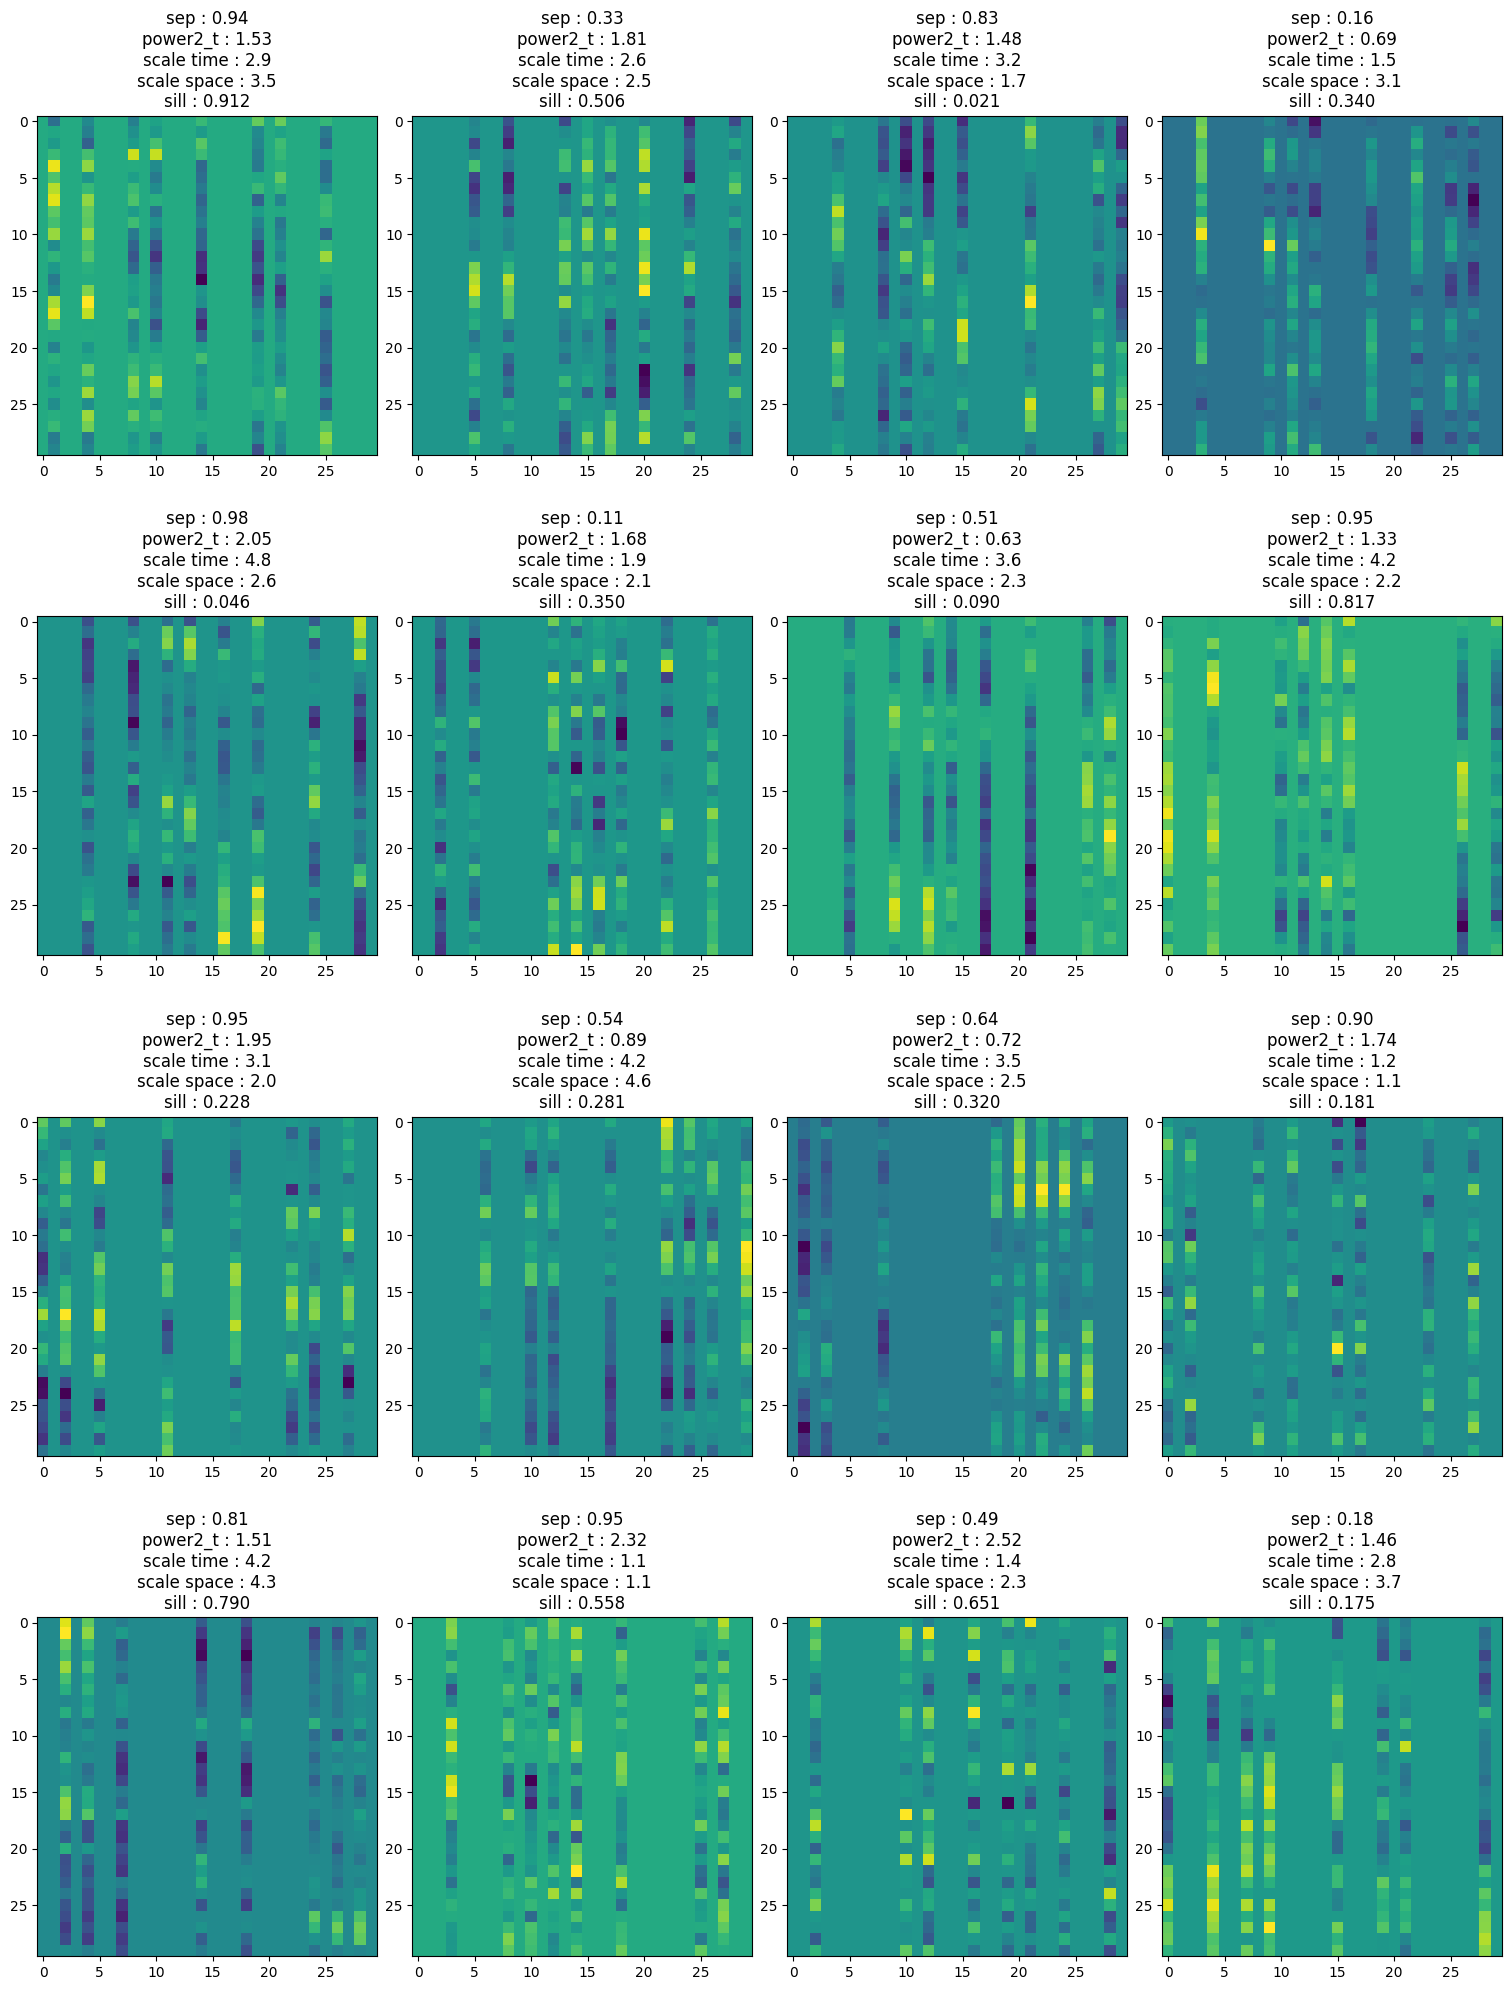

In [205]:
m=0

fig, ax = plt.subplots(4, 4, figsize=(15, 20), constrained_layout=True)
for i in range(4):
    for j in range(4):
        ax[i,j].imshow(dataset_sep[i*4+j][0][m][0], aspect='equal')
        ax[i,j].set_title(to_title(dataset_sep[i*4+j][1][0].detach().numpy()))

## General functions

In [24]:
class CNN_network(nn.Module):
    def __init__(self, in_channels=2, hidden=32, out_dim=4, option="2D-CNN", nls=False):
        super().__init__()

        self.option_type = option
        self.nls = nls

        if option == "2D-CNN" : 
        
            self.conv2d = nn.Sequential(
                nn.Conv2d(in_channels=in_channels, out_channels=hidden, kernel_size=5, stride=1, padding=1),
                nn.ReLU(),
                nn.Conv2d(in_channels=hidden, out_channels=hidden, kernel_size=3, stride=1, padding=1),
                nn.ReLU(),
            )
            
            self.pool2d = nn.AdaptiveAvgPool2d(1) 

        else : 

            self.conv1d = nn.Sequential(
                nn.Conv1d(in_channels=in_channels, out_channels=hidden, kernel_size=5, stride=1, padding=1),
                nn.ReLU(),
                nn.Conv1d(in_channels=hidden, out_channels=hidden, kernel_size=3, stride=1, padding=1),
                nn.ReLU(),
            )
            
            self.pool1d = nn.AdaptiveAvgPool1d(1) 
    
            if option == "CNN" :
            
                self.conv1d_T = nn.Sequential(
                    nn.Conv1d(in_channels=hidden, out_channels=hidden, kernel_size=5, stride=1, padding=1),
                    nn.ReLU(),
                    nn.Conv1d(in_channels=hidden, out_channels=hidden, kernel_size=3, stride=1, padding=1),
                    nn.ReLU(),
                )
    
            elif option == "LSTM" :
    
                self.lstm = nn.LSTM(input_size=hidden, hidden_size=hidden, num_layers=2, batch_first=True, bidirectional=False)  

        
        self.dense = nn.Sequential(
            nn.Linear(hidden+4*nls, hidden),
            nn.ReLU(),
            nn.Linear(hidden, out_dim)  
        )

    def forward(self, x, deepset=None, theta=None):
        
        B,C,T,S = x.shape

        # print(x.shape)

        if self.option_type == "2D-CNN" :

            summary = self.conv2d(x)

            summary = self.pool2d(summary).view(B, -1)

        else : 

            x = x.permute(0,3,1,2).reshape(B*T, C, S)  
    
            # print(x.shape)
    
            time_summary = self.conv1d(x)                               # (B*T,hidden_dim,S)
            time_summary = self.pool1d(time_summary).view(B*T,-1)       # (B*T,hidden_dim)
    
            # print(time_summary.shape)
    
            time_summary = time_summary.view(B, T, -1).permute(0, 2, 1)                        # (B, hidden_dim, T)
    
            # print(time_summary.shape)
    
            if self.option_type == "CNN":
                summary = self.conv1d_T(time_summary)            # (B,hidden+1,T)
                summary = summary.mean(dim=2)                    # (B,hidden+1)
                
            elif self.option_type == "LSTM":    
                time_summary = time_summary.permute(0,2,1)       # (B,T,hidden+1)
                summary,_ = self.lstm(time_summary)              # (B,T,hidden+1)
                summary = summary.mean(dim=1)                    # (B,hidden+1)
    
        # print(summary.shape)
    
        if not self.nls :
            summary = global_mean_pool(summary, deepset)   # [nb_deepset, hidden_dim]
        else :
            summary = torch.cat((summary, theta.float()),dim=1)

        # print(summary.shape)
        
        out = self.dense(summary)
        return out

In [25]:
def train_test(model, optimizer, loader, test_loader, epoch_loss):
    all_loss_train = [] 
    all_loss_test = []

    loss_final_train = None
    theta_final_test = None
    
    t = tqdm(range(0, n_epochs),total=n_epochs)
    
    time_train = time.time()
    
    for epoch in t:
        
        losses = epoch_loss(model, optimizer, loader, save_full=(epoch == n_epochs-1))
    
        t.set_description(f"Epoch {epoch+1}/{n_epochs}")
        t.set_postfix(loss=f"{losses["mean"][0]:.4f}, {losses["mean"][1]:.4f}, {losses["mean"][2]:.4f} and {losses["mean"][3]:.4f}")

        all_loss_train.append(losses["mean"])   

        if "full" in losses:                          
            loss_final_train = losses["full"] 
            
        if (epoch+1)%n_epochs_test == 0 :
                
            time_test = time.time()
                
            for data_test, theta_test, deepset_test in test_loader :
                    
                output = model(data_test.float(), torch.arange(len(theta_test)))
                loss_vec = torch.abs(output - theta_test)

                all_loss_test.append(loss_vec.mean(dim=0).detach().cpu())

                theta_final_test = output.detach().cpu()
                    
            time_test = time.time() - time_test
            time_train -= time_test
    
    time_train = time.time() - time_train
    
    print(f"Time to train : {time_train:.2f}s")
    
    print(f"Train loss : adv {all_loss_train[-1][0].tolist()} | range time {all_loss_train[-1][1].tolist()} | range space {all_loss_train[-1][2].tolist()} | std {all_loss_train[-1][3].tolist()}")

    print(f"Test loss : adv {all_loss_test[-1][0].tolist()} | range time {all_loss_test[-1][1].tolist()} | range space {all_loss_test[-1][2].tolist()} | std {all_loss_test[-1][3].tolist()}")
    return all_loss_train, time_train, loss_final_train, all_loss_test, time_test, theta_final_test


def train_simple(model, optimizer, loader, epoch_loss):
    all_loss_train = [] 

    loss_final_train = None
    
    t = tqdm(range(0, n_epochs),total=n_epochs)
    
    time_train = time.time()
    
    for epoch in t:
        
        losses = epoch_loss(model, optimizer, loader)
    
        t.set_description(f"Epoch {epoch+1}/{n_epochs}")
        t.set_postfix(loss=losses)

        all_loss_train.append(losses["mean"])   

        if "full" in losses:                          
            loss_final_train = losses["full"] 
    
    time_train = time.time() - time_train
    
    print(f"Time to train : {time_train:.2f}s")
    
    print("Train loss :", all_loss_train[-1])

    return all_loss_train, time_train

## CNN

### Functions

In [26]:
def epoch_cnn(model, optimizer, loader, save_full=False):
    
    model.train()
    MAE = torch.nn.L1Loss(reduction="none")
    
    losses_theta0 = []
    losses_theta1 = []
    losses_theta2 = []
    losses_theta3 = []
    full_losses = [] 

    for i, (batched_data, theta, deepset) in enumerate(loader):
                
        optimizer.zero_grad()

        batched_data, theta, deepset = batched_data.to(device).float(), theta.to(device), deepset.to(device) 

        # print(batched_data.shape, theta.shape, deepset.shape)

        deepset_mapped, theta = map_deepset(deepset, theta)

        # print(deepset_mapped.shape, theta.shape)
        
        output = model(batched_data, deepset_mapped)
        
        loss_vec = MAE(output, theta)
        
        loss = loss_vec.mean()
        loss.backward()
        optimizer.step()

        losses_theta0.append(loss_vec[:,0].mean().item())
        losses_theta1.append(loss_vec[:,1].mean().item())
        losses_theta2.append(loss_vec[:,2].mean().item())
        losses_theta3.append(loss_vec[:,3].mean().item())

        if save_full:                             
            full_losses.append(loss_vec.detach().cpu())

    mean = torch.tensor([np.mean(losses_theta0), np.mean(losses_theta1), np.mean(losses_theta2), np.mean(losses_theta3)]).detach().cpu()
    # std  = torch.tensor([np.std(losses_theta0),  np.std(losses_theta1)])

    result = {
        "mean": mean, 
        # "std": std
    }

    if save_full:
        result["full"] = torch.cat(full_losses, dim=0)    

    return result


In [27]:
def plot_loss(all_loss_train, all_loss_test, dataset, theta_names, theta_colors):
    fig_cnn, ax = plt.subplots(1, len(theta_names), figsize=(20, 7), constrained_layout=True)
    based, _ = baseline_mae(dataset)

    for i, name in enumerate(theta_names):
    
        ax[i].plot([l[i] for l in all_loss_train], theta_colors[i]['train'], label='train '+name)
        ax[i].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l[i] for l in all_loss_test], theta_colors[i]['test'], label='test '+name)
        
        ax[i].axhline(based[i],color=theta_colors[i]['baseline'], ls='--', label='baseline '+name)
        
        ax[i].set_title('Evolution of '+name)
        ax[i].set_xlabel('epochs')
        ax[i].set_ylabel('MAE')
        ax[i].legend()

    return fig_cnn

### Train and Test

#### Advection

Epoch 250/250: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 250/250 [40:00<00:00,  9.60s/it, loss=0.4893, 0.0389, 0.0343 and 0.0499]


Time to train : 2409.08s
Train loss : adv 0.48927353153768927 | range time 0.038929692602941414 | range space 0.03430551065639738 | std 0.049920873913180994
Test loss : adv 0.5264796343408525 | range time 0.04029413777019377 | range space 0.037784832388625414 | std 0.06282813877724508


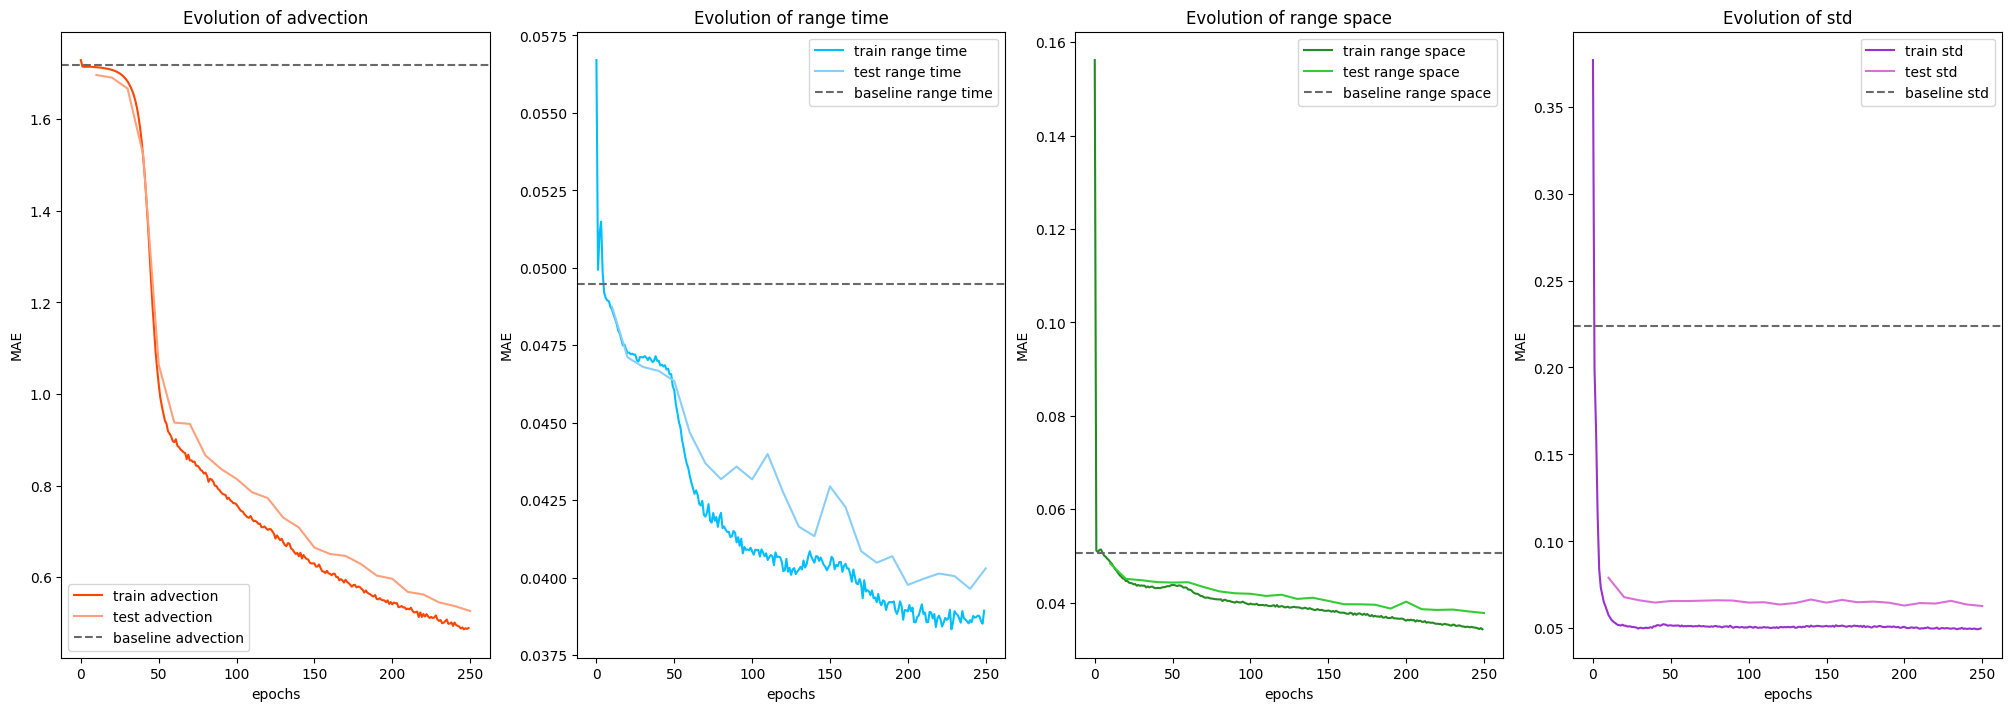

In [284]:
model_grid_2D = CNN_network(in_channels=2, option="2D-CNN").to(device)

optimizer_grid_2D = torch.optim.Adam(model_grid_2D.parameters(), lr=5e-5)

all_loss_train_grid_2D, time_train_grid_2D, loss_final_train_grid_2D, all_loss_test_grid_2D, time_test_grid_2D, theta_final_test_grid_2D = train_test(model_grid_2D, optimizer_grid_2D, loader_grid, loader_grid_test, epoch_cnn)
fig_grid_2D = plot_loss(all_loss_train_grid_2D, all_loss_test_grid_2D, dataset_grid, theta_names_adv, theta_colors)

In [285]:
fig_grid_2D.savefig(res_path+"/adv/loss_evolution"+"/grid_2D_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_grid_2D.state_dict(), res_path+"/adv/models"+"/grid_2D_model.pth")

Epoch 250/250: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 250/250 [40:12<00:00,  9.65s/it, loss=1.7140, 0.0437, 0.0392 and 0.0475]


Time to train : 2421.90s
Train loss : adv 1.7139541016470639 | range time 0.04372191113319805 | range space 0.03918753709082399 | std 0.047499744417805516
Test loss : adv 1.6960870031360538 | range time 0.044222108027675955 | range space 0.04047369597784378 | std 0.06160892930918037


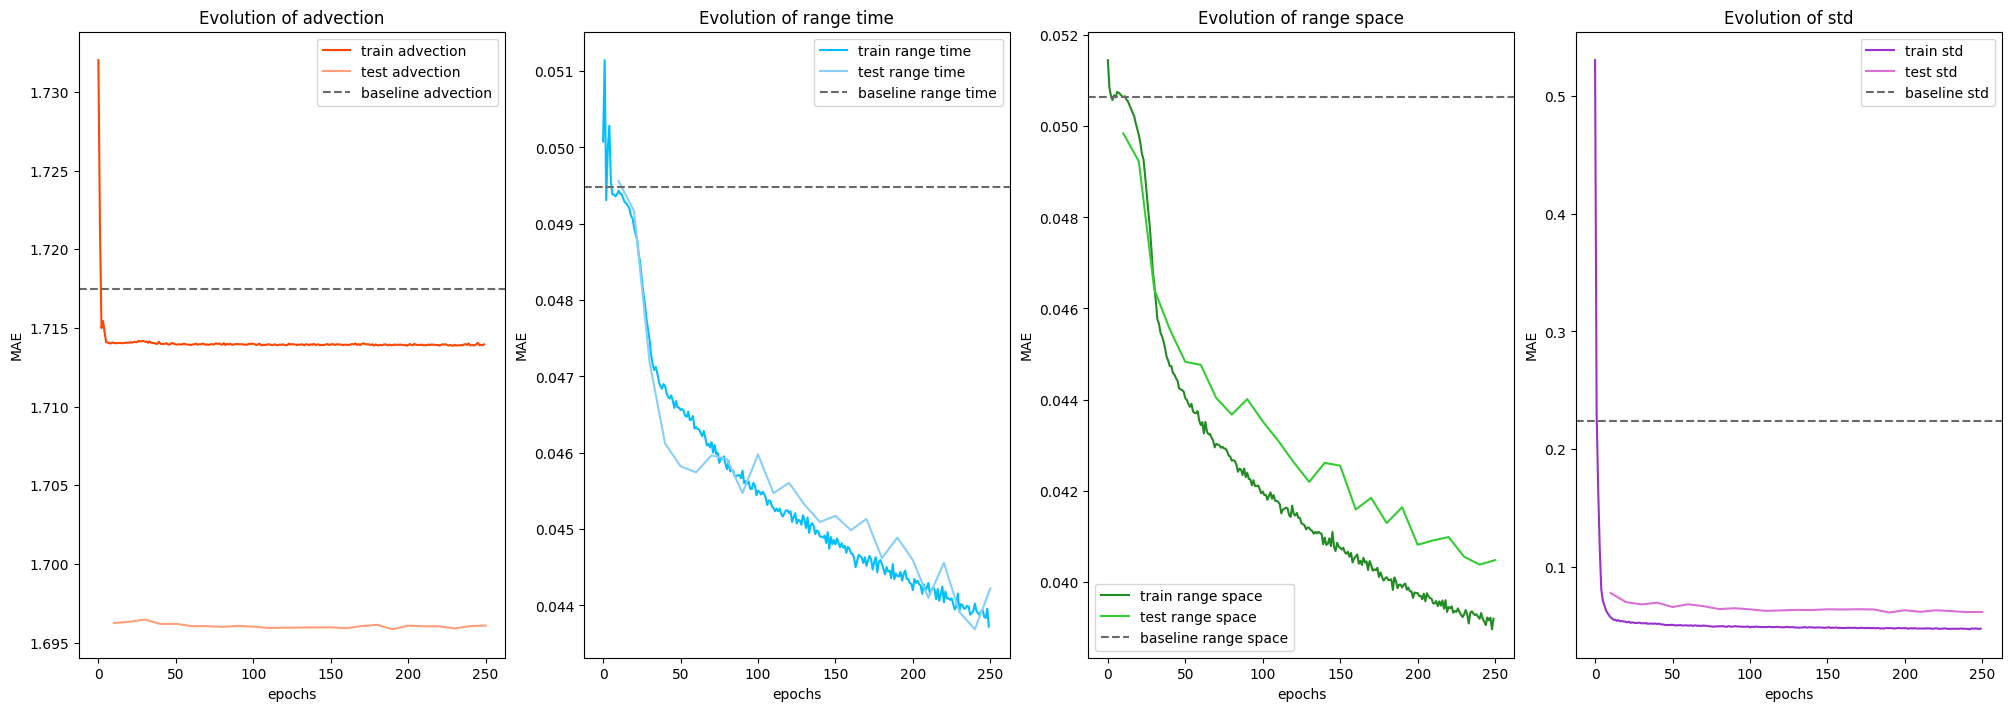

In [292]:
model_grid_1D1D = CNN_network(in_channels=2, option="CNN").to(device)

optimizer_grid_1D1D = torch.optim.Adam(model_grid_1D1D.parameters(), lr=5e-5)

all_loss_train_grid_1D1D, time_train_grid_1D1D, loss_final_train_grid_1D1D, all_loss_test_grid_1D1D, time_test_grid_1D1D, theta_final_test_grid_1D1D = train_test(model_grid_1D1D, optimizer_grid_1D1D, loader_grid, loader_grid_test, epoch_cnn)
fig_grid_1D1D = plot_loss(all_loss_train_grid_1D1D, all_loss_test_grid_1D1D, dataset_grid, theta_names_adv, theta_colors)

In [293]:
fig_grid_1D1D.savefig(res_path+"/adv/loss_evolution"+"/grid_1D1D_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_grid_1D1D.state_dict(), res_path+"/adv/models"+"/grid_1D1D_model.pth")

In [28]:
model_grid_1D1D = CNN_network(in_channels=2, option="CNN").to(device)
model_grid_1D1D.load_state_dict(torch.load("results/super_spationtemporal_2D_bis/adv/models/grid_1D1D_model.pth"))

model_grid_2D = CNN_network(in_channels=2, option="2D-CNN").to(device)
model_grid_2D.load_state_dict(torch.load("results/super_spationtemporal_2D_bis/adv/models/grid_2D_model.pth"))

                
for data_test, theta_test, deepset_test in loader_grid_test :
                    
    theta_final_test_grid_2D = model_grid_2D(data_test.float(), torch.arange(len(theta_test))).detach().numpy()
    theta_final_test_grid_1D1D = model_grid_1D1D(data_test.float(), torch.arange(len(theta_test))).detach().numpy()
    

#### Separability

Epoch 250/250: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 250/250 [38:37<00:00,  9.27s/it, loss=0.1102, 0.4905, 0.5609 and 0.0580]


Time to train : 2325.00s
Train loss : adv 0.1101841445386896 | range time 0.49052829094802664 | range space 0.5608813958623778 | std 0.058002032349468456
Test loss : adv 0.12668430254637103 | range time 0.49971371054204344 | range space 0.6866464363045034 | std 0.07013104759005057


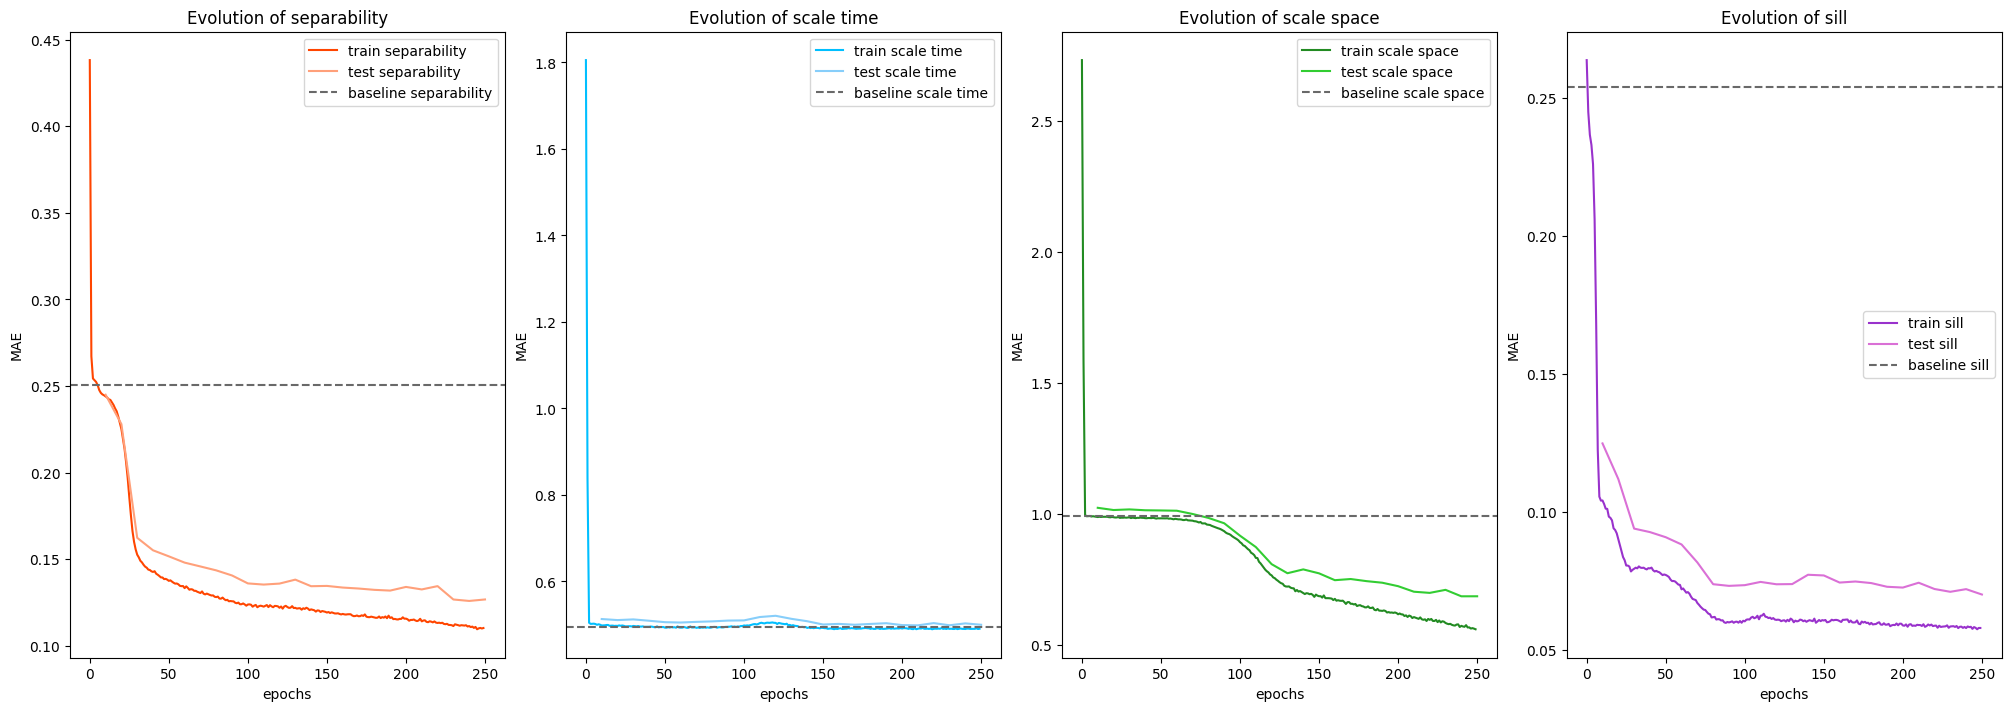

In [194]:
model_sep_2D = CNN_network(in_channels=2, option="2D-CNN").to(device)

optimizer_sep_2D = torch.optim.Adam(model_sep_2D.parameters(), lr=5e-5)

all_loss_train_sep_2D, time_train_sep_2D, loss_final_train_sep_2D, all_loss_test_sep_2D, time_test_sep_2D, theta_final_test_sep_2D = train_test(model_sep_2D, optimizer_sep_2D, loader_sep, loader_sep_test, epoch_cnn)
fig_sep_2D = plot_loss(all_loss_train_sep_2D, all_loss_test_sep_2D, dataset_sep, theta_names_sep, theta_colors)

In [195]:
fig_sep_2D.savefig(res_path+"/sep/loss_evolution"+"/sep_2D_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_sep_2D.state_dict(), res_path+"/sep/models"+"/sep_2D_model.pth")

Epoch 250/250: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 250/250 [35:42<00:00,  8.57s/it, loss=0.0975, 0.4841, 0.9563 and 0.0587]


Time to train : 2150.67s
Train loss : adv 0.09747967469539218 | range time 0.4840728103559613 | range space 0.9562861415315744 | std 0.05873024472891278
Test loss : adv 0.11925523222520136 | range time 0.49562792381933607 | range space 0.9886410880340313 | std 0.07479105435617814


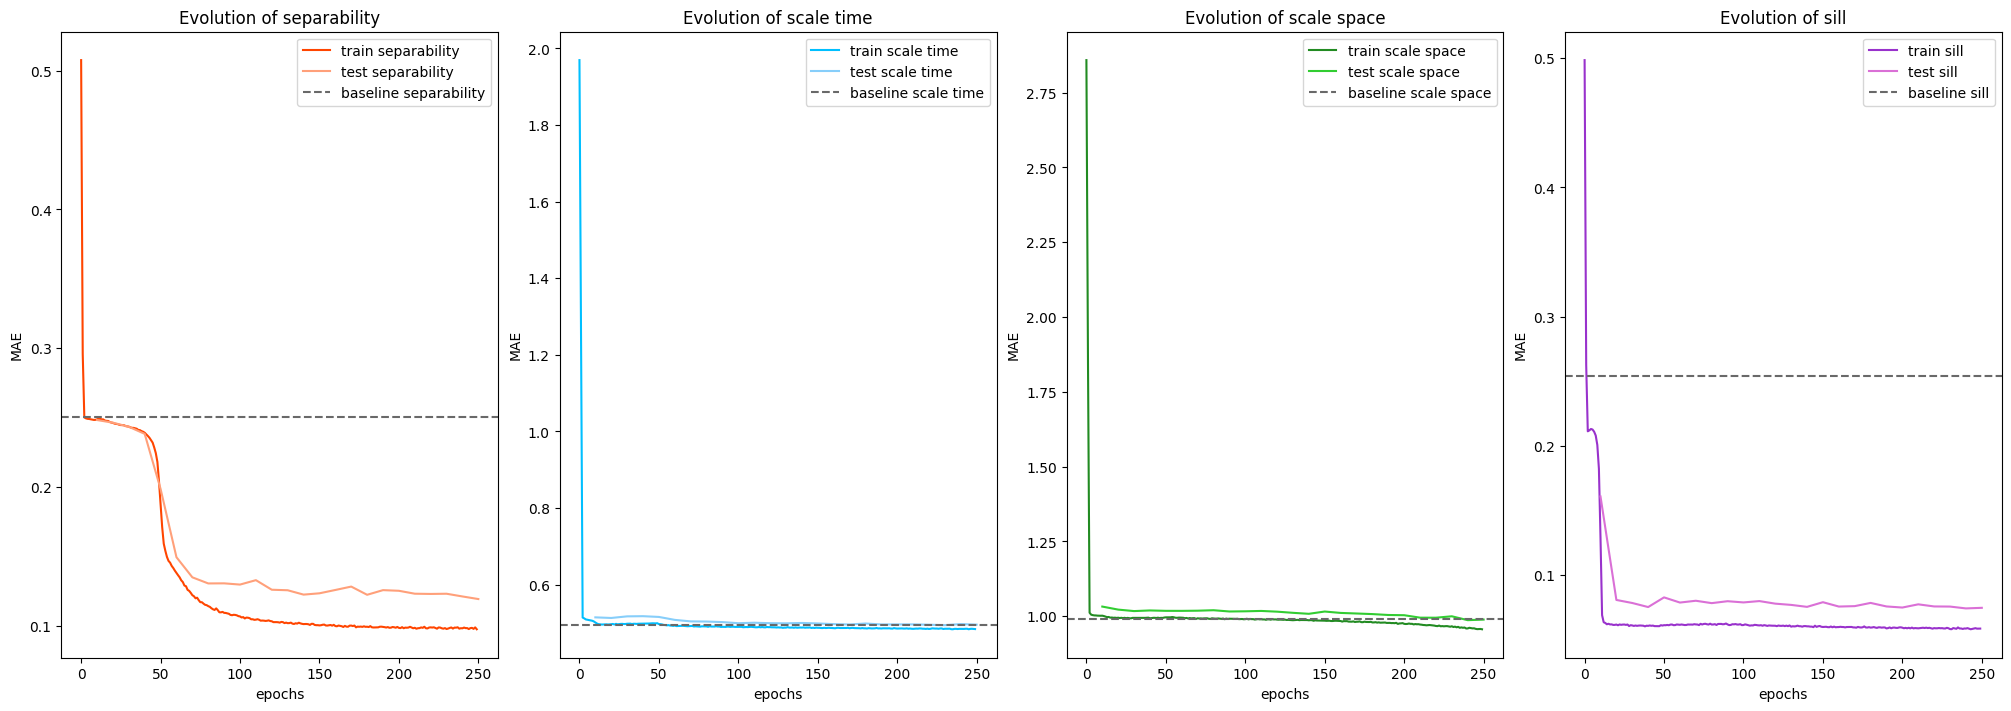

In [196]:
model_sep_1D1D = CNN_network(in_channels=2, option="CNN").to(device)

optimizer_sep_1D1D = torch.optim.Adam(model_sep_1D1D.parameters(), lr=5e-5)

all_loss_train_sep_1D1D, time_train_sep_1D1D, loss_final_train_sep_1D1D, all_loss_test_sep_1D1D, time_test_sep_1D1D, theta_final_test_sep_1D1D = train_test(model_sep_1D1D, optimizer_sep_1D1D, loader_sep, loader_sep_test, epoch_cnn)
fig_sep_1D1D = plot_loss(all_loss_train_sep_1D1D, all_loss_test_sep_1D1D, dataset_sep, theta_names_sep, theta_colors)

In [197]:
fig_sep_1D1D.savefig(res_path+"/sep/loss_evolution"+"/sep_1D1D_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_sep_1D1D.state_dict(), res_path+"/sep/models"+"/sep_1D1D_model.pth")

## NLS

### Functions

In [198]:
class GridNLSDataset(GridDataset):
    def __init__(self, dataset_grid: GridDataset):

        self.__dict__ = dataset_grid.__dict__.copy()

        self.pi = torch.stack([
            torch.randperm(self.theta_size)
            for _ in range(self.deepset_size)
        ])

    def __len__(self):
        return 2 * self.theta_size

    def __getitem__(self, idx):
        is_perm = idx // self.theta_size
        idx = idx % self.theta_size

        batch = np.load(f"{self.path}/samples/sample_{idx}.npy")

        if self.missing_ratio > 0:
            batch = add_missing_mask(batch, self.missing_ratio)

        base_theta = self.get_theta()

        if is_perm:
            theta = base_theta[self.pi[:, idx]]
        else:
            theta = base_theta[idx].expand(self.deepset_size, -1)

        classi = torch.full(
            (self.deepset_size,),
            is_perm,
            dtype=torch.int64
        )

        return torch.from_numpy(batch), theta, classi

In [199]:
class SepNLSDataset(SepDataset):
    def __init__(self, dataset_sep: SepDataset):

        self.__dict__ = dataset_sep.__dict__.copy()

        self.pi = torch.stack([
            torch.randperm(self.theta_size)
            for _ in range(self.deepset_size)
        ])

    def __len__(self):
        return 2 * self.theta_size

    def __getitem__(self, idx):
        is_perm = idx // self.theta_size
        idx = idx % self.theta_size
        
        batch = np.load(f"{self.path}/samples/sample_{idx}.npy")

        if self.missing_ratio > 0:
            batch = add_missing_mask(batch, self.missing_ratio)

        base_theta = self.get_theta()

        if is_perm:
            theta = base_theta[self.pi[:, idx]]
        else:
            theta = base_theta[idx].expand(self.deepset_size, -1)

        classi = torch.full(
            (self.deepset_size,),
            is_perm,
            dtype=torch.int64
        )

        return torch.from_numpy(batch), theta, classi

In [200]:
dataset_grid_nls = GridNLSDataset(dataset_grid)
dataset_grid_nls_test = GridNLSDataset(dataset_grid_test)

dataset_grid_nls = GridNLSDataset(GridDataset.load(data_path+"/adv/train"))
dataset_grid_nls_test = GridNLSDataset(GridDataset.load(data_path+"/adv/test"))

loader_grid_nls = DataLoader(dataset_grid_nls, batch_size, shuffle=True,collate_fn=deepset_collate)
loader_grid_nls_test = DataLoader(dataset_grid_nls_test, 1, shuffle=False,collate_fn=deepset_collate)

In [201]:
dataset_sep_nls = SepNLSDataset(dataset_sep)
dataset_sep_nls_test = SepNLSDataset(dataset_sep_test)

dataset_sep_nls = SepNLSDataset(SepDataset.load(data_path+"/sep/train"))
dataset_sep_nls_test = SepNLSDataset(SepDataset.load(data_path+"/sep/test"))

loader_sep_nls = DataLoader(dataset_sep_nls, batch_size, shuffle=True,collate_fn=deepset_collate)
loader_sep_nls_test = DataLoader(dataset_sep_nls_test, 1, shuffle=False,collate_fn=deepset_collate)

In [202]:
def epoch_nls(model, optimizer, loader):
    
    model.train()
    CE = nn.CrossEntropyLoss() # Towards Reliable Simulation-Based Inference with Balanced Neural Ratio Estimation ???
    
    losses = []

    for i, (batched_data, theta, classi) in enumerate(loader):
        optimizer.zero_grad()

        batched_data, theta, classi = batched_data.to(device), theta.to(device), classi.to(device).flatten()

        # batched_data = batched_data.reshape(-1, 1, batched_data.shape[2], batched_data.shape[3])   
        # theta = theta.reshape(-1, theta.shape[2])   
        # classi = classi.reshape(-1)   

        output = model(batched_data.float(), theta=theta)
        
        batch_loss = CE(output, classi)
        
        batch_loss.backward()
        optimizer.step()
        
        losses.append(batch_loss.mean().item())

    return {"mean":np.mean(losses)}

### Train

Epoch 250/250: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 250/250 [1:17:24<00:00, 18.58s/it, loss={'mean': np.float64(0.054997768769972026)}]


Time to train : 4645.00s
Train loss : 0.054997768769972026


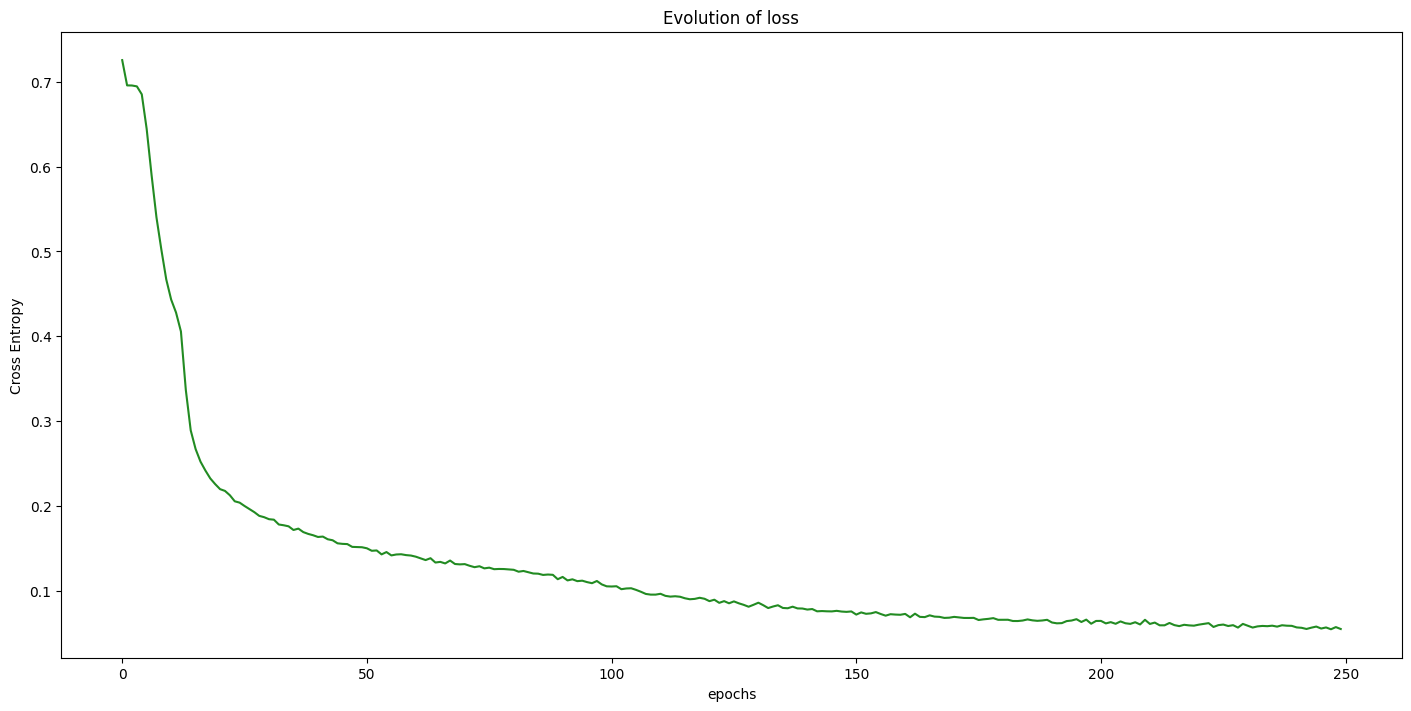

In [203]:
model_grid_nls = CNN_network(in_channels=2, option="2D-CNN", nls=True).to(device)
# model_nls.load_state_dict(torch.load(f"results/global_smaller-{n_train}×{m_train}ntrain-{n_test}×{m_test}ntest"+"/models"+"/nls-classifier_model.pth", weights_only=True))

optimizer_grid_nls = torch.optim.Adam(model_grid_nls.parameters(), lr=1e-3)

all_loss_train_grid_nls, time_train_grid_nls = train_simple(model_grid_nls, optimizer_grid_nls, loader_grid_nls, epoch_nls)

fig_grid_nls, ax = plt.subplots(1, 1, figsize=(14, 7), constrained_layout=True)
ax.plot(all_loss_train_grid_nls, 'forestgreen')

ax.set_title('Evolution of loss')
ax.set_xlabel('epochs')
ax.set_ylabel('Cross Entropy')

fig_grid_nls.savefig(res_path+"/adv/loss_evolution"+"/NLS-classifier_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_grid_nls.state_dict(), res_path+"/adv/models"+"/NLS-classifier_model.pth")

Epoch 250/250: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 250/250 [1:21:17<00:00, 19.51s/it, loss={'mean': np.float64(0.08567190893460065)}]


Time to train : 4877.04s
Train loss : 0.08567190893460065


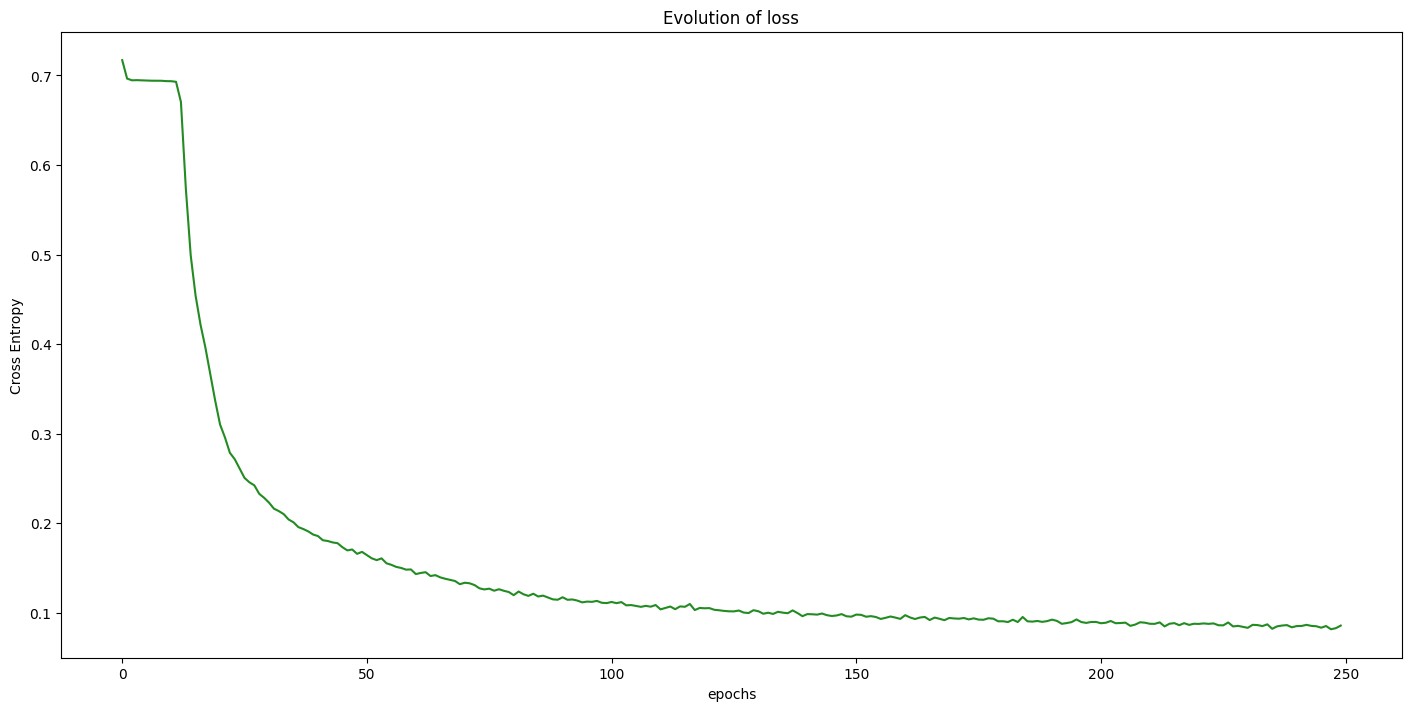

In [204]:
model_sep_nls = CNN_network(in_channels=2, option="2D-CNN", nls=True).to(device)
# model_nls.load_state_dict(torch.load(f"results/global_smaller-{n_train}×{m_train}ntrain-{n_test}×{m_test}ntest"+"/models"+"/nls-classifier_model.pth", weights_only=True))

optimizer_sep_nls = torch.optim.Adam(model_sep_nls.parameters(), lr=1e-3)

all_loss_train_sep_nls, time_train_sep_nls = train_simple(model_sep_nls, optimizer_sep_nls, loader_sep_nls, epoch_nls)

fig_sep_nls, ax = plt.subplots(1, 1, figsize=(14, 7), constrained_layout=True)
ax.plot(all_loss_train_sep_nls, 'forestgreen')

ax.set_title('Evolution of loss')
ax.set_xlabel('epochs')
ax.set_ylabel('Cross Entropy')

fig_sep_nls.savefig(res_path+"/sep/loss_evolution"+"/NLS-classifier_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_sep_nls.state_dict(), res_path+"/sep/models"+"/NLS-classifier_model.pth")

### Test

#### Grid search

In [36]:
def estimate_likelihood_surface(model, simu, theta_grid):
    
    model.eval()
    
    L_values = []
    simu = simu.to(device)
    
    with torch.no_grad():
        t = tqdm(theta_grid)
        for theta in t:
            
            theta_t = theta.clone().unsqueeze(0).tile((len(simu), 1)).to(device)
            # print(simu.shape, theta_t.shape)
            h = model(simu.float(), theta=theta_t)
            
            # p = torch.softmax(h, dim=1)[:, 1]   # h[:,1]
            # L = p / (1 - p)
            # L_values.append(L)

            logL = h[:,1] - h[:,0]
            L_values.append(logL)

            # L = torch.log(L.unsqueeze(0)).detach().numpy()
            # L = torch.tensor(lg.predict_proba(L.T)[0, 1])     
            
    return torch.stack(L_values)

In [400]:
range_min, range_max = 0.05, 0.25
adv_min, adv_max = -3, 3
std_min, std_max = 0.1, 1.0

# bounds = [(adv_min, adv_max), (range_min, range_max), (range_min, range_max)]

n_range = 5
n_adv = 5
n_std = 5

range_vals = torch.linspace(range_min, range_max, n_range)
adv_vals = torch.linspace(adv_min, adv_max, n_adv)
std_vals = torch.linspace(std_min, std_max, n_std)

S, R1, R2, F = torch.meshgrid(
    adv_vals,
    range_vals,
    range_vals,
    std_vals,
    indexing='ij'
)

theta_grid = torch.stack(
    [
        S.flatten(),
        R1.flatten(),
        R2.flatten(),
        F.flatten()
    ],
    dim=1
)

In [401]:
theta_grid.shape

torch.Size([625, 4])

In [402]:
time_test_nls = time.time()

with torch.no_grad():
    for data_test, theta_test, _ in loader_grid_nls_test : 
        L_values = estimate_likelihood_surface(model_nls, data_test, theta_grid)
        output = theta_grid[torch.argmax(L_values,dim=0)]
        all_loss_test_nls = torch.abs(output - theta_test.squeeze(1)).detach().numpy()
        theta_final_nls = output.detach().numpy()
        
time_test_nls = time.time() - time_test_nls

print(f"\nTime to test : {time_test_nls:.2f}s")

print("Test loss :", np.mean(all_loss_test_nls,axis=0), "±", np.std(all_loss_test_nls,axis=0))

 39%|█████████████████████████▊                                        | 244/625 [00:00<00:00, 2773.95it/s]


KeyboardInterrupt: 

#### Optim

In [205]:
def nls_optim(data, model_nls, theta0, activation=lambda x:x):  # lambda x:x # torch.exp

    def obj(theta):
        theta_t = activation(theta.unsqueeze(0).to(device))
        # theta_t = theta.unsqueeze(0).to(device)
        h = model_nls(data, theta=theta_t)

        logL = h[:,1] - h[:,0]
        return logL

    res = torchmin.minimize(
        obj,
        theta0,
        method="bfgs",
        options={
            "max_iter": 500,
            "lr": 0.2,
        },
        return_all=True
    )
    return activation(res.x), activation(res.allvecs[-2])


In [206]:
all_loss_test_grid_nls = []

time_test_grid_nls = time.time()

theta0=torch.tensor((0.,.1,.1, .2))
activation=lambda x:torch.sigmoid(x)*torch.tensor([6.,.25,.25,1.])-torch.tensor([3.,0,0,0])

for i, (data_test, theta_test, _) in enumerate(loader_grid_nls_test) : 

    if i == test_size :
        break

    output, output_not_nan = nls_optim(data_test.float(),model_grid_nls,theta0,activation)

    all_loss_test_grid_nls.append(np.abs(output - theta_test).detach().cpu())

    if torch.isnan(all_loss_test_grid_nls[-1])[0,0] :
        all_loss_test_nls[-1] = output_not_nan

    if i%100 == 0:
        print(i,end="|")

    # print(output, np.array(theta_test))

time_test_grid_nls = time.time() - time_test_grid_nls

print(f"\n\nTime to test : {time_test_grid_nls:.2f}s")

print("Test loss :", np.mean(all_loss_test_grid_nls,axis=0), "±", np.std(all_loss_test_grid_nls,axis=0))

/tmp/ipykernel_914891/205363271.py:15: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  all_loss_test_grid_nls.append(np.abs(output - theta_test).detach().cpu())


0|100|200|300|400|500|600|700|800|900|

Time to test : 43.36s
Test loss : [[0.28726519 0.0345848  0.03238215 0.07542653]] ± [[0.29884188 0.02741828 0.02395616 0.06042587]]


In [232]:
all_loss_test_sep_nls = []

time_test_sep_nls = time.time()

theta0=torch.tensor((.1,2.,2., .1))
# activation=lambda x:torch.sigmoid(x)*torch.tensor([1.,3.,5.,1.])
activation=lambda x:torch.sigmoid(x)*torch.tensor([1.,4.,6.,1.])-torch.tensor([0,1.,1.,0])

for i, (data_test, theta_test, _) in enumerate(loader_sep_nls_test) : 

    if i == test_size :
        break

    output, output_not_nan = nls_optim(data_test.float(),model_sep_nls,theta0,activation)

    all_loss_test_sep_nls.append(np.abs(output - np.array(theta_test)).detach().cpu())

    if torch.isnan(all_loss_test_sep_nls[-1])[0,0] :
        # all_loss_test_nls[-1] = output_not_nan
        all_loss_test_sep_nls[-1] = output_not_nan

    if i%100 == 0:
        print(i,end="|")

    # print(output, np.array(theta_test))

time_test_sep_nls = time.time() - time_test_sep_nls

print(f"\n\nTime to test : {time_test_sep_nls:.2f}s")

print("Test loss :", np.mean(all_loss_test_sep_nls,axis=0), "±", np.std(all_loss_test_sep_nls,axis=0))

/tmp/ipykernel_914891/3050144177.py:16: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  all_loss_test_sep_nls.append(np.abs(output - np.array(theta_test)).detach().cpu())
/tmp/ipykernel_914891/3050144177.py:16: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  all_loss_test_sep_nls.append(np.abs(output - np.array(theta_test)).detach().cpu())


0|100|200|300|400|500|600|700|800|900|

Time to test : 38.86s
Test loss : [[0.10002809 0.73170652 0.53581285 0.15122909]] ± [[0.10106394 0.58459424 0.49355755 0.14931847]]


## Maximum likelihood

In [277]:
def matern_covariance_from_coords(coords, adv, range_time, range_space, std):

    t, s = coords

    s = s + t.copy() * adv

    sigma, nu = std, 1.

    d2 = ((t - t.T)**2 / range_time**2) + ((s - s.T)**2 / range_space**2)
    d = np.sqrt(d2 + 1e-12) 

    res = (sigma**2 * (2**(1-nu) / gamma(nu)) * (np.sqrt(2*nu) * d)**nu * kv(nu, np.sqrt(2*nu) * d))
    
    np.fill_diagonal(res, sigma**2)

    return res

In [278]:
def nll(theta, coords, values, eps=1e-6): 
    # https://soft.mines-paristech.fr/gstlearn/demos-latest/python/Tuto_LogLikelihood.html

    adv, range_time, range_space, std = theta
    cov = matern_covariance_from_coords(coords, adv, range_time, range_space, std)
    cov += eps * np.eye(cov.shape[0])

    L = linalg.cholesky(cov) 

    # solve Σ^{-1} @ values 
    alpha = linalg.cho_solve((L, False), values) 

    # Compute values.T @ Σ^{-1} @ values 
    quad = float(np.dot(values,alpha))

    # det term, https://math.stackexchange.com/questions/3158303/using-cholesky-decomposition-to-compute-covariance-matrix-determinant
    logdet = 2.0 * np.sum(np.log(np.diag(L)))

    return 0.5 * (logdet + quad + values.size * np.log(2.0 * np.pi))

In [279]:
range_min, range_max = 0.05, 0.5
adv_min, adv_max = -3, 3
std_min, std_max = .1, 1.

bounds = [(adv_min, adv_max), (range_min, range_max), (range_min, range_max), (std_min, std_max)]

In [280]:
def mle_matern(coords, values, theta0=(0,.2, .2, .5)):

    def obj(theta):
        return nll(theta, coords, values)

    res = minimize(obj, theta0, method="Nelder-Mead", bounds=bounds, options={"maxiter":2000})
    return res.x, res

In [281]:
all_loss_test_ML = np.zeros((len(dataset_grid_test),len(theta_names)))
theta_final_ML = np.zeros((len(dataset_grid_test),len(theta_names)))

grid = np.meshgrid(np.linspace(0,1,time_size), np.linspace(0,1,time_size), indexing='ij')
grid = ([grid[0].reshape(-1, 1), grid[1].reshape(-1, 1)])

time_test_ML = time.time()

for i, (data_test, theta_test, _) in enumerate(dataset_grid_test) : 

    if i==20:
        break

    mask = data_test[0,1].to(bool).flatten()

    grid_mask = (grid[0][mask], grid[1][mask])
    data = data_test[0,0].flatten()[mask]
    
    output, _ = mle_matern(grid, data_test[0,0].flatten().detach().numpy())

    all_loss_test_ML[i] = np.abs(output - theta_test.flatten().detach().numpy())
    theta_final_ML[i] = output

    t_time_simu_ML = time.time()
    print(i, end='|')
    print(output, theta_test.flatten().detach().numpy())
    

    # print(f"| RANGE {output[0]:.4f} - {theta_test[0]:.4f} = {abs(output[0]-theta_test[0]):.4f} | STD {output[1]:.4f} - {theta_test[1]:.4f} = {abs(output[1]-theta_test[1]):.4f} |")

time_test_ML = time.time() - time_test_ML

print(f"\n\nTime to test : {time_test_ML:.2f}s")

print("Test loss :", np.mean(all_loss_test_ML,axis=0), "±", np.std(all_loss_test_ML,axis=0))

0|[-0.02995026  0.16294246  0.05        0.76920228] [-1.          0.10534254  0.15179864  0.70833249]
1|[0.04139908 0.10055267 0.05014748 0.74512512] [2.         0.085052   0.21091    0.81427286]
2|[0.23373297 0.05       0.05       0.11266433] [2.         0.24007505 0.07272581 0.10640145]
3|[0.01733886 0.25936079 0.05       1.        ] [2.         0.23635917 0.1894243  0.72005244]
4|[-0.01105864  0.15459908  0.05000017  0.63846599] [-3.          0.15727533  0.24975771  0.57533612]
5|[0.00169565 0.05       0.05921983 1.        ] [-3.          0.10466557  0.0663641   0.65523316]
6|[0.00355808 0.3047751  0.05       1.        ] [1.         0.23264954 0.23844125 0.93254741]
7|[0.0013419  0.5        0.05       0.41618399] [0.         0.21891177 0.0752709  0.36460011]
8|[0.00530944 0.13064724 0.05       0.23290001] [1.         0.06226069 0.14105428 0.19068344]
9|[0.00345979 0.11166181 0.05000001 0.90478964] [0.         0.0509036  0.10981353 0.74270566]
10|[-0.00572807  0.18737126  0.05       

## Conclusion

In [29]:
option="adv"

if option=="adv" :
    based, _ = baseline_mae(dataset_grid)
    theta_names = theta_names_adv
else : 
    based, _ = baseline_mae(dataset_sep)
    theta_names = theta_names_sep

NameError: name 'loss_final_train_grid_2D' is not defined

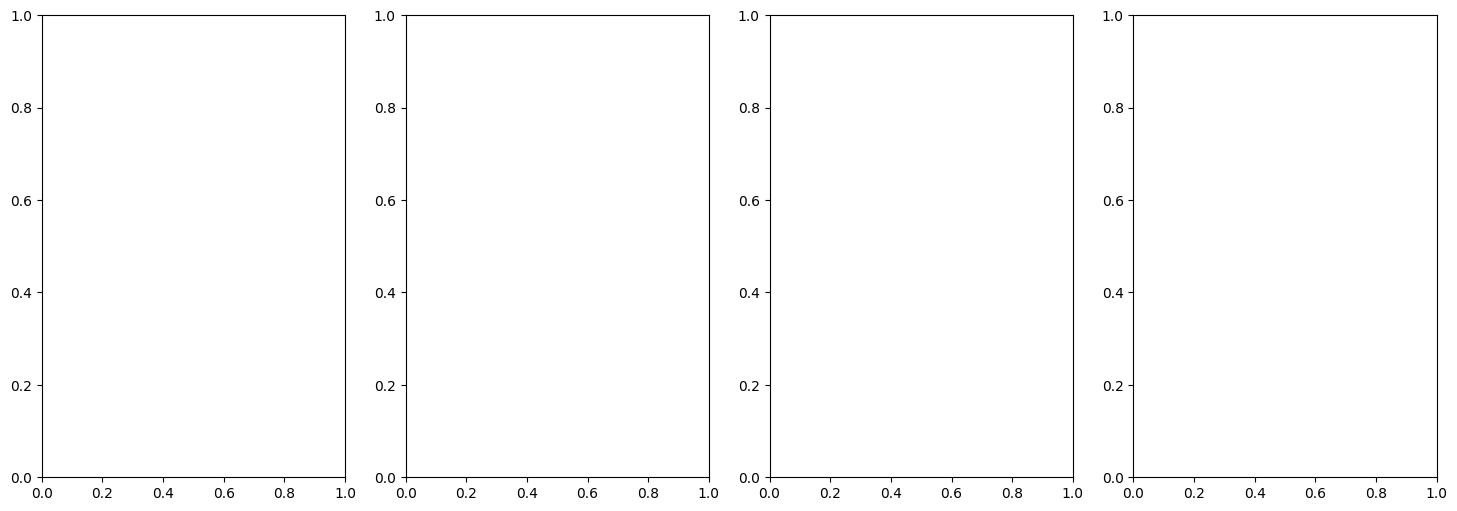

In [30]:
methods = ['2D-CNN', '1D1D-CNN']

fig_box_train, axs = plt.subplots(1, len(theta_names), figsize=(18, 6))

    
for i, name in enumerate(theta_names):

    if option=="adv" :
        losses = [
            loss_final_train_grid_2D[:, i],
            loss_final_train_grid_1D1D[:, i],
        ]
    else :
        losses = [
            loss_final_train_sep_2D[:, i],
            loss_final_train_sep_1D1D[:, i],
        ]
    
    axs[i].boxplot(losses, tick_labels=methods, patch_artist=True,
                   boxprops=dict(facecolor=theta_colors[i]['train'], alpha=0.6), 
                   medianprops=dict(linestyle='-', linewidth=2, color='black'))
    axs[i].set_title("MAE – "+name)
    axs[i].set_ylabel("MAE")
    
    axs[i].axhline(based[i],color=theta_colors[i]['baseline'], ls='--', label='baseline '+name)
    # axs[i].legend()

plt.suptitle("Train error comparaison")
plt.tight_layout()
plt.show()

# fig_box_train.savefig(res_path+"/conclusion_graphs"+"/score_train.pdf", format="pdf", bbox_inches="tight")
# fig_box_train.savefig(res_path+"/"+option+"/conclusion_graphs"+"/score_train.png", format="png", bbox_inches="tight")

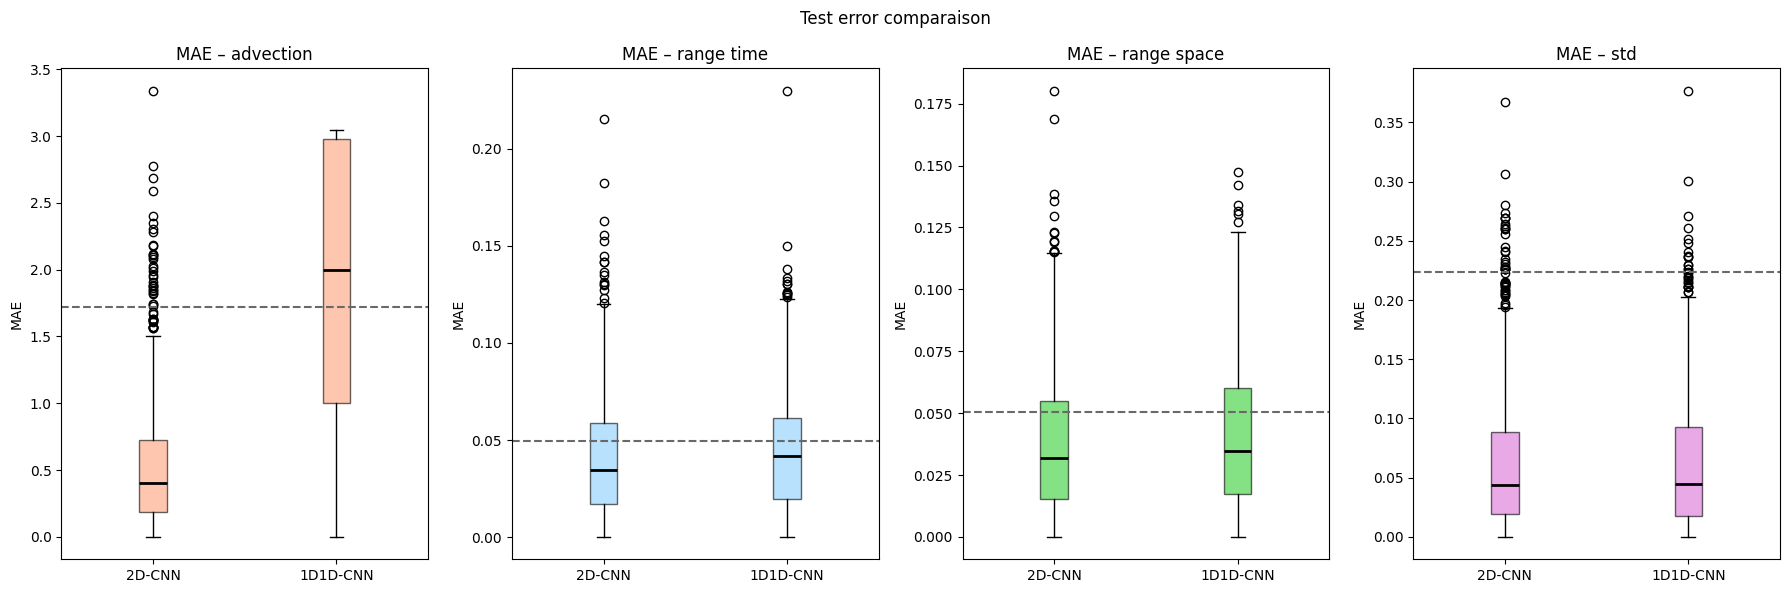

In [296]:
methods = ['2D-CNN', '1D1D-CNN'] #,'NLS-2D-CNN']

fig_box_test, axs = plt.subplots(1, len(theta_names), figsize=(18, 6))
    
for i, name in enumerate(theta_names):

    if option=="adv" :
        losses = [
            abs(theta_final_test_grid_2D[:, i] - dataset_grid_test.get_theta()[:, i]),
            abs(theta_final_test_grid_1D1D[:, i] - dataset_grid_test.get_theta()[:, i]),
            # torch.cat(all_loss_test_grid_nls,dim=0)[:,i],
            # all_loss_test_ML[:20,i]
        ]
    else:
        losses = [
            abs(theta_final_test_sep_2D[:, i] - dataset_sep_test.get_theta()[:, i].detach().numpy()),
            abs(theta_final_test_sep_1D1D[:, i] - dataset_sep_test.get_theta()[:, i].detach().numpy()),
            torch.cat(all_loss_test_sep_nls,dim=0)[:,i],
        ]
    
    axs[i].boxplot(losses, tick_labels=methods, patch_artist=True,
                   boxprops=dict(facecolor=theta_colors[i]['test'], alpha=0.6), 
                   medianprops=dict(linestyle='-', linewidth=2, color='black'))
    axs[i].set_title("MAE – "+name)
    axs[i].set_ylabel("MAE")
    
    axs[i].axhline(based[i],color=theta_colors[i]['baseline'], ls='--', label='baseline '+name)
    # axs[i].legend()

plt.suptitle("Test error comparaison")
plt.tight_layout()
plt.show()

# fig_box_test.savefig(res_path+"/conclusion_graphs"+"/score_test.pdf", format="pdf", bbox_inches="tight")
fig_box_test.savefig(res_path+"/"+option+"/conclusion_graphs"+"/score_test.png", format="png", bbox_inches="tight")

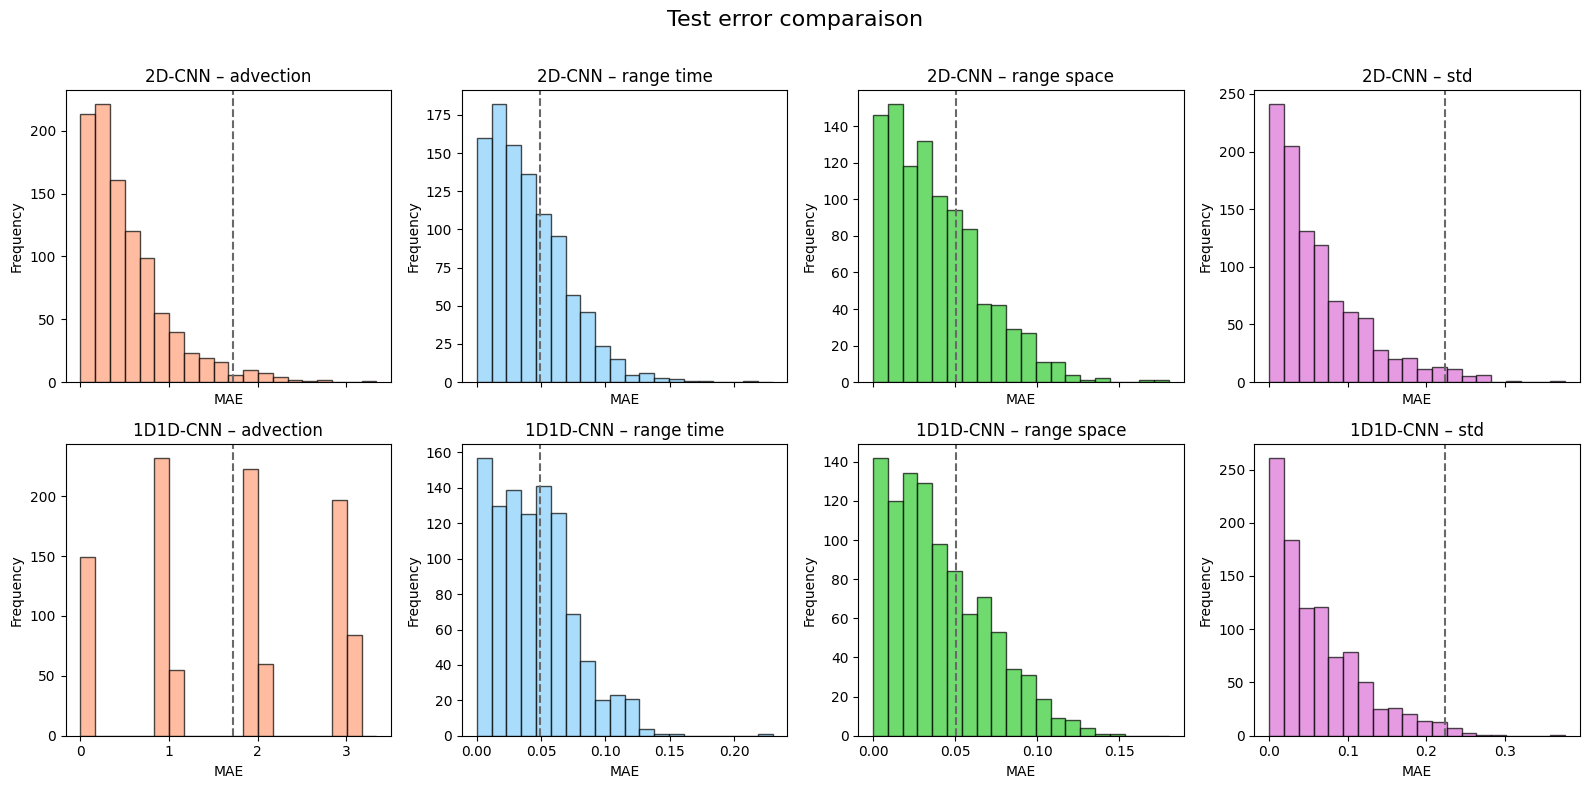

In [297]:
methods = ['2D-CNN' , '1D1D-CNN'] #,'NLS-2D-CNN']

fig_hist, axs = plt.subplots(len(methods),len(theta_names), figsize=(len(theta_names)*4, 4*len(methods)),squeeze=False,sharex='col')
fig_hist.suptitle("Test error comparaison", fontsize=16)

for i, name in enumerate(theta_names):

    if option=="adv" :
        losses = [
            abs(theta_final_test_grid_2D[:, i] - dataset_grid_test.get_theta()[:, i]),
            abs(theta_final_test_grid_1D1D[:, i] - dataset_grid_test.get_theta()[:, i]),
            # torch.cat(all_loss_test_grid_nls,dim=0)[:,i],
            # all_loss_test_ML[:20,i]
        ]
    else:
        losses = [
            abs(theta_final_test_sep_2D[:, i] - dataset_sep_test.get_theta()[:, i]),
            abs(theta_final_test_sep_1D1D[:, i] - dataset_sep_test.get_theta()[:, i]),
            torch.cat(all_loss_test_sep_nls,dim=0)[:,i],
        ]

    global_min = min(l.min() for l in losses)
    global_max = max(l.max() for l in losses)
    bins = np.linspace(global_min, global_max, 21)
    
    for j, method in enumerate(methods):


        axs[j, i].hist(losses[j], bins=bins, color=theta_colors[i]['test'], alpha=0.7, edgecolor='black')
        axs[j, i].axvline(based[i], color=theta_colors[i]['baseline'], linestyle='--', label='Baseline range')
        axs[j, i].set_title(f"{method} – {name}")
        axs[j, i].set_xlabel("MAE")
        axs[j, i].set_ylabel("Frequency")
        # axs[i, j].legend()

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

fig_hist.savefig(res_path+"/"+option+"/conclusion_graphs"+"/score_test_hist.png", format="png", bbox_inches="tight")

In [290]:
### Time



def format_seconds(s):
    h, m, s = int(s//3600), int((s%3600)//60), int(s%60)
    return f"{h}h{m}m{s}s" if h > 0 else (f"{m}m{s}s" if m > 0 else f"{s}s")

if option=="adv":
    methods = ['2D-CNN' , '1D1D-CNN','NLS-2D-CNN']
    simu_times = [time_simu_grid, time_simu_grid, time_simu_grid]
    train_times = [time_train_grid_2D, time_train_grid_1D1D, time_train_grid_nls]   
    test_times = [time_test_grid_2D, time_test_grid_1D1D,time_test_grid_nls] 
else :
    methods = ['2D-CNN' , '1D1D-CNN','NLS-2D-CNN']
    simu_times = [time_simu_sep, time_simu_sep, time_simu_sep]
    train_times = [time_train_sep_2D, time_train_sep_1D1D, time_train_sep_nls]   
    test_times = [time_test_sep_2D, time_test_sep_1D1D,time_test_sep_nls] 

x = np.arange(len(methods))
width = 0.3

fig_time, ax = plt.subplots(figsize=(8, 5))

bar0 = ax.bar(x - width, simu_times, width, label='Simulation', color='forestgreen')
bar1 = ax.bar(x, train_times, width, label='Train', color='royalblue')
bar2 = ax.bar(x + width, test_times, width, label='Test', color='firebrick')

for b, t in zip([bar0, bar1, bar2], [simu_times, train_times, test_times]):
    labels = [format_seconds(val) for val in t]
    ax.bar_label(b, labels=labels, padding=3)

ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylabel("Time")
ax.set_title("Computation time comparison")
ax.legend()

ax.margins(y=0.2) 

plt.tight_layout()
plt.show()

# fig_time.savefig(res_path+"/conclusion_graphs"+"/time.pdf", format="pdf", bbox_inches="tight")
fig_time.savefig(res_path+"/"+option+"/conclusion_graphs"+"/time.png", format="png", bbox_inches="tight")

NameError: name 'time_train_grid_1D1D' is not defined

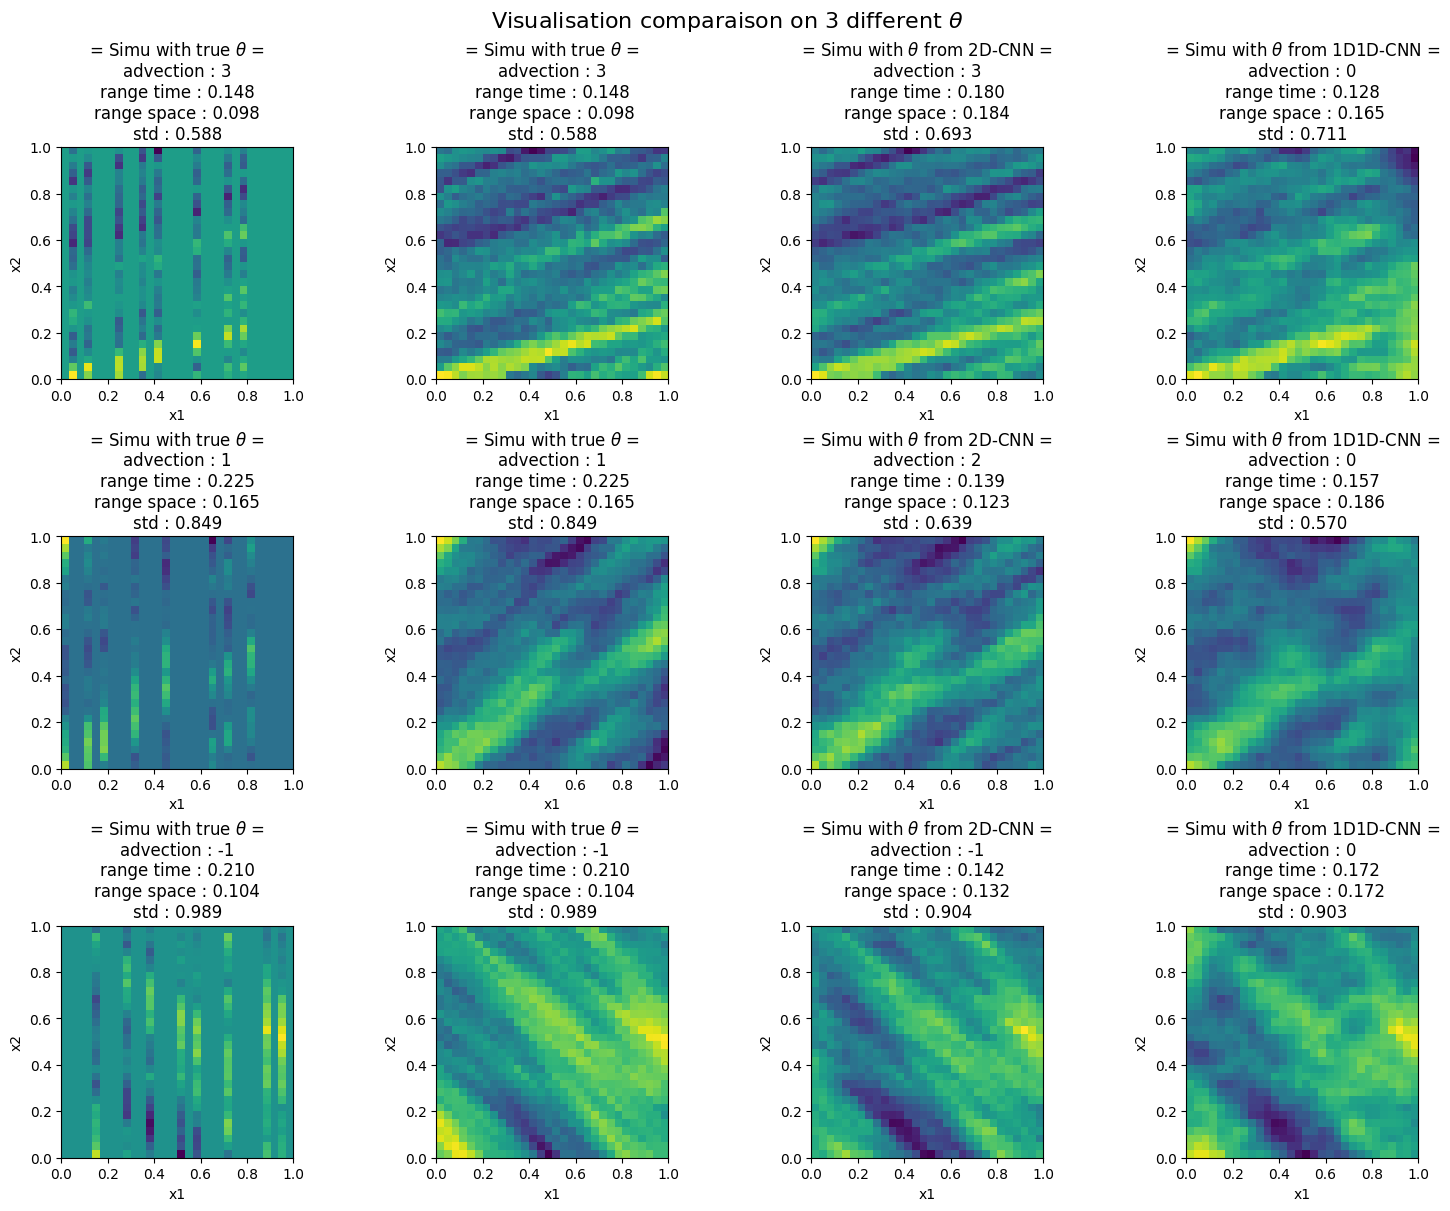

In [256]:
def matern_adv_cov(coords1, coords2, adv, range_time, range_space, std):

    t1 = coords1[:, 0].reshape(-1, 1)
    s1 = coords1[:, 1].reshape(-1, 1)
    
    t2 = coords2[:, 0].reshape(1, -1)
    s2 = coords2[:, 1].reshape(1, -1)

    adv = int(round(adv))

    # Advection
    s1 = s1 + adv * t1
    s2 = s2 + adv * t2

    nu=1.0

    d2 = ((t1 - t2)**2) / range_time**2 \
       + ((s1 - s2)**2) / range_space**2
    d = np.sqrt(d2 + 1e-12)

    K = std**2 * (2**(1-nu)) / gamma(nu) * (np.sqrt(2*nu) * d)**nu * kv(nu, np.sqrt(2*nu) * d)

    return K

def kriging_matern_adv(sample,theta,time_size,space_size):

    adv, range_time, range_space, std = theta

    range_time = max(range_time, 0.05)  
    range_space = max(range_space, 0.05)  
    std = max(std, 0.1)  

    y, mask_obs = sample[0].reshape(-1), np.array(sample[1], dtype=bool).reshape(-1)

    t = np.linspace(0, 1, time_size)
    s = np.linspace(0, 1, space_size)

    coords = np.array([
        (ti, si)
        for ti in t
        for si in s
    ])  

    y_obs = y[~mask_obs]
    coords_obs = coords[~mask_obs]
    coords_miss = coords[mask_obs]

    cov_oo = matern_adv_cov(
        coords_obs, coords_obs,
        adv, range_time, range_space, std
    )

    cov_mo = matern_adv_cov(
        coords_miss, coords_obs,
        adv, range_time, range_space, std
    )

    cov_oo += 1e-6 * np.eye(cov_oo.shape[0])

    y_miss = cov_mo @ np.linalg.solve(cov_oo, y_obs)

    y_full = y.copy()
    y_full[mask_obs] = y_miss

    return y_full.reshape(time_size, space_size)



methods = ['2D-CNN', '1D1D-CNN']
if option=="adv":
    models = [model_grid_2D, model_grid_1D1D]
    def to_title(vals):
        return f"advection : {int(np.round(vals[0]))}\nrange time : {vals[1]:.3f}\nrange space : {vals[2]:.3f}\nstd : {vals[3]:.3f}"
else:
    models = [model_sep_2D, model_sep_1D1D]
    def to_title(vals):
        return f"separability : {vals[0]}\nrange time : {vals[1]:.3f}\nrange space : {vals[2]:.3f}\nstd : {vals[3]:.3f}"

n = 3
p = len(methods)+1
fig_map, axs = plt.subplots(n, p+1, figsize=(5*p,n*4), constrained_layout=True)

for i in range(n):
    if option=="adv":
        sample, true_theta = dataset_grid.get_fulldata_mask(i)
    else:
        sample, true_theta, _ = dataset_sep_test[i]

    axs[i,1].imshow(sample[0], cmap='viridis', extent=[0,1,0,1])
    axs[i,1].set_xlabel('x1')
    axs[i,1].set_ylabel('x2')
    axs[i,1].set_title(r'= Simu with true $\theta$ ='+'\n'+to_title(true_theta))

    sample[0][np.array(sample[1], dtype=bool)] = 0
    
    axs[i,0].imshow(sample[0], cmap='viridis', extent=[0,1,0,1])
    axs[i,0].set_xlabel('x1')
    axs[i,0].set_ylabel('x2')
    axs[i,0].set_title(r'= Simu with true $\theta$ ='+'\n'+to_title(true_theta))
    
        

    
    for j, (method, model) in enumerate(zip(methods, models)) :
        
        theta_pred = model(
            torch.from_numpy(sample).unsqueeze(0).float(), 
            deepset=torch.tensor([0])
        )[0].detach().numpy()
        
        if option=="adv":
            sample_uncond = simulate_matern_grid(
                time_size,
                space_size,
                np.round(theta_pred[0]).astype(int),
                np.maximum(theta_pred[1],np.array(0.05)),
                np.maximum(theta_pred[2],np.array(0.05)),
                np.maximum(theta_pred[3],np.array(0.1)),
                deepset_size=1
            )[0][0]

            # print(sample[1].shape)
            # print(sample_uncond.shape)
            # print(np.where(sample[1].astype(bool),sample_uncond, 0).shape)
            # print(np.stack([np.where(sample[1].astype(bool),sample_uncond, 0),sample[1]]).shape)

            sample_krig_uncond = kriging_matern_adv(
                np.stack([np.where(~sample[1].astype(bool),sample_uncond, 0),sample[1]]),
                theta_pred,
                time_size=time_size,
                space_size=space_size
            )    
            
            sample_krig = kriging_matern_adv(
                sample,
                theta_pred,
                time_size=time_size,
                space_size=space_size
            )         

            sample_pred = sample_uncond - sample_krig_uncond + sample_krig
            # sample_pred = sample_krig
        else:
            s = np.expand_dims(np.arange(1, space_size + 1),1)
            params = {
                'mean': 0,
                'sill': theta_pred[0].detach().numpy(),       
                'smooth_s': 1.0,   
                'scale_s':theta_pred[1].detach().numpy(),    
                'power_t': 0.5,    
                'scale_t': theta_pred[2].detach().numpy(),     
                'sep': theta_pred[3].detach().numpy(),        
                'power2_t': theta_pred[3].detach().numpy()*2
            }
            sample_pred =  simulate_spatio_temporal(params, time_size, s).T
            
        axs[i,j+2].imshow(sample_pred, cmap='viridis', extent=[0,1,0,1]) #, origin='lower', extent=[0,1,0,1], cmap='viridis')
            
        axs[i,j+2].set_xlabel('x1')
        axs[i,j+2].set_ylabel('x2')
        axs[i,j+2].set_title(r'= Simu with $\theta$ from '+method+' =\n'+to_title(theta_pred))
        

fig_map.suptitle(r"Visualisation comparaison on "+str(n)+r" different $\theta$", fontsize=16)

# fig_map.savefig(res_path+"/conclusion_graphs"+"/visualisation.pdf", format="pdf", bbox_inches="tight")
# fig_map.savefig(res_path+"/"+option+"/conclusion_graphs"+"/visualisation.png", format="png", bbox_inches="tight")

plt.show()